<a href="https://colab.research.google.com/github/FrancoVenesia/TP_AA1_Perez_Venesia_Welsechen_CruzElizondoRios/blob/main/TP_2/TP-clasificacion-AA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico 2: Predicción de lluvia en Australia
### Aprendizaje Automático I
### Facultad de Ciencias Exactas, Ingeniería y Agrimensura (FCEIA) - Universidad Nacional de Rosario (UNR)

### Integrantes:
- Welschen. Joaquín
- Venesia. Franco
- Elizondo Rios, Iñaki Cruz

Dataset: `weatherAUS_2026C2.csv`

- El dataset contiene información climática de Australia 
de  los  últimos  diez  años,  incluyendo  si  para  el  día  siguiente  llovió  o  no  en  la  columna 
`RainTomorrow`.  

- El  objetivo  del  trabajo  práctico  es  armar un ejecutable de Docker para 
predecir, a las 23:59hs de cada día, si el día siguiente va a llover o no. 

## Consignas:


1. Realizar un análisis descriptivo, que ayude a la comprensión del problema, de cada
una de las variables involucradas, detallando: características, comportamiento y
rango de variación. ¿Qué es cada variable?
Debe incluir:
    -  Análisis y decisión sobre datos faltantes.
    -  Visualización de datos (por ejemplo histogramas, scatterplots entre variables,
    diagramas de caja)
    -  ¿Está balanceado el dataset? ¿Por qué cree que hacemos esta pregunta?
    -  Codificación de variables categóricas (si se van a utilizar para predicción).
    -  Matriz de correlación de variables.
    -  Estandarización/escalado de datos.
    -  Validación cruzada train - test. Realizar una división del conjunto de datos en conjuntos de entrenamiento y prueba (y si se quiere, se puede incluir
    validación, que luego será útil) en el MOMENTO donde lo crean adecuado.

2. Implementar la solución del problema de clasificación con regresión logística.
    - Obtener las métricas adecuadas (accuracy, precision, recall, F1 score, entre
    otras, ¡investiguen adicionales!). Graficar matrices de confusión para cada
    modelo. Analizar “falsos negativos” y “falsos positivos”, ¿qué significa cada
    uno?
    - Trazar curvas ROC para cada modelo. Comenten cuáles serían los umbrales
    adecuados a utilizar; ¿cómo podrían calcular el mejor umbral? ¿Es 0.5 el
    mejor?
    - ¿Creen que han conseguido un buen fitting?
3.  Implementar un modelo base.  
    - Repetir los pasos del ítem 2 que sean necesarios.

## Diccionario de variables (Qué son los datos?)



Cada fila es una observación diaria de una estación meteorológica. Las variables son:

| Variable | Descripción | Tipo | Unidad |
|---|---|---|---|
| `Unnamed: 0` | Índice de fila del archivo original. No aporta información. | entero | - |
| `Date` | Fecha de la observación. | fecha | - |
| `Location` | Ciudad / estación donde se tomó la observación (49 distintas). | categórica nominal | - |
| `MinTemp` | Temperatura mínima del día. | numérica continua | °C |
| `MaxTemp` | Temperatura máxima del día. | numérica continua | °C |
| `Rainfall` | Lluvia caída en las 24 h previas a las 9 am. | numérica continua | mm |
| `Evaporation` | Evaporación (tanque clase A) en las 24 h previas a las 9 am. | numérica continua | mm |
| `Sunshine` | Horas de sol del día. | numérica continua | horas |
| `WindGustDir` | Dirección de la ráfaga de viento más fuerte del día (16 puntos cardinales). | categórica nominal | - |
| `WindGustSpeed` | Velocidad de esa ráfaga máxima. | numérica continua | km/h |
| `WindDir9am`, `WindDir3pm` | Dirección del viento a las 9 am y a las 3 pm. | categórica nominal | - |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad media del viento en los 10 minutos previos a las 9 am / 3 pm. | numérica continua | km/h |
| `Humidity9am`, `Humidity3pm` | Humedad relativa a las 9 am / 3 pm. | numérica continua | % |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica reducida al nivel del mar a las 9 am / 3 pm. | numérica continua | hPa |
| `Cloud9am`, `Cloud3pm` | Fracción del cielo cubierta por nubes a las 9 am / 3 pm. | numérica discreta (0 a 8) | octas |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 am / 3 pm. | numérica continua | °C |
| `RainToday` | `Yes` si `Rainfall` supera 1 mm, `No` en otro caso. | categórica binaria | - |
| `RainTomorrow` | **Variable objetivo**: `Yes` si al día siguiente llovió más de 1 mm. | categórica binaria | - |
| `RainfallTomorrow` | Lluvia caída al día siguiente. | numérica continua | mm |




Primeras observaciones:

- `RainTomorrow`  es lo que queremos predecir: a las 23:59 no la conocemos y  `RainfallTomorrow` debe tener informacion compatible con la misma.

    - Si empleamos `RainfallTomorrow`, el modelo tendría información que no va a estar disponible al momento de predecir (*fuga de datos*), así que debemos prescindir de ella para construir el modelo. El resto de las variables sí se conocen a las 23:59 del día.

- También eliminaremos `Unnamed: 0`, que es sólamente un índice.

## 0. Librerias y configuraciones globales

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer  # habilita IterativeImputer (es experimental en scikit-learn)
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_curve, roc_auc_score, auc)

SEMILLA = 42
pd.set_option('display.max_columns', 50)

## 1. Análisis descriptivo

### 1.1 Exploración y limpieza de datos

#### 1.1.1 Carga y primera inspección

In [2]:
#Carga del dataset original
df = pd.read_csv('weatherAUS_2026C2.csv')
#Dimensiones del dataset
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')


Filas: 145412 | Columnas: 25


In [3]:
#Informacion de tipos de datos y Cantidad de valores no nulos por columna
df.info(max_cols=len(df.columns))

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

Observaciones:
- A la variable `Date` se le debe aplicar un cambio de **Dtype** para poder descomponer la fecha.
- Se observan valores faltantes en muchas variables (incluyendo la variable objetivo), habrá que elaborar una **estrategia de imputación** para las que vayamos a utilizar.

In [4]:
# Primeros 5 registros
display(df.head(5))

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,WNW,19.0,25.0,68.8,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,23.0,40.1,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,WSW,20.0,27.0,36.2,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,E,10.0,10.0,45.8,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,NW,6.0,17.0,83.5,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


Observaciones:
- Los registros están agrupados por estación y, dentro de cada una, ordenados por fecha. Se deben ordenar los datos de manera **cronológica** al momento de realizar el split para la validación cruzada.
- Las variables que especifican la **dirección del viento** (`WindGustDir`, `WindDir9am`, `WindDir3pm`) deben transformarse a forma cíclica para que el modelo pueda interpretarlas adecuadamente.
- Las variables `RainToday` y `RainTomorrow` deben codificarse.

In [5]:
#Medidas descriptivas numéricas
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,145412.0,72728.184393,41990.722236,0.0,36362.75,72727.5,109093.25,145458.0
MinTemp,143928.0,12.196528,6.417956,-9.7,7.60,12.0,16.90,34.1
MaxTemp,144159.0,23.223064,7.135927,-5.1,17.90,22.6,28.20,49.1
Rainfall,142152.0,2.361516,8.479338,0.0,0.00,0.0,0.80,371.0
Evaporation,82658.0,5.468616,4.193871,0.0,2.60,4.8,7.40,145.0
Sunshine,75616.0,7.611241,3.785612,0.0,4.80,8.4,10.60,14.5
WindGustSpeed,135159.0,40.036668,13.648259,6.0,31.00,38.0,48.00,135.0
WindSpeed9am,143645.0,14.067277,8.936768,0.0,7.00,13.0,19.00,130.0
WindSpeed3pm,142351.0,18.661899,8.865457,0.0,12.00,18.0,24.00,86.0
Humidity9am,142759.0,68.861521,19.062866,0.0,57.00,69.9,83.10,100.0


Anomalías:
- `Evaporation`: el máximo (145 mm) está muy lejos del percentil 75 (7.4 mm) y de la media (5.5 mm). En 1.1.2 analizamos de dónde vienen estos valores.
- `Cloud9am` y `Cloud3pm`: el máximo es 9, pero la escala de octas va de 0 (cielo despejado) a 8 (cielo cubierto). El 9 se usa cuando el cielo no se puede observar (por ejemplo, por niebla), así que no pertenece a la escala y hay que tratarlo.

**Resumen de tareas a realizar:**

Antes del split (son transformaciones fila por fila, que no usan información de otros registros):
- Descartar las columnas `Unnamed: 0` y `RainfallTomorrow`, y las filas sin `RainTomorrow`.
- Corregir el valor 9 de `Cloud9am` y `Cloud3pm`.
- Convertir `Date` a fecha, extraer el mes y el día del año, y ordenar los datos cronológicamente (el split se hace con cortes en el tiempo).
- Codificar `RainToday` y `RainTomorrow` como 0/1.
- Codificar de forma cíclica (seno y coseno) el día del año y las direcciones del viento.
- Agrupar las estaciones en regiones climáticas y codificarlas con one-hot.

Después del split:
- Imputar los valores faltantes de las variables que usa el modelo.
- Escalar las variables numéricas.

#### 1.1.2 Limpieza inicial

Verificación de fuga de datos

In [6]:
# Verificamos si RainTomorrow se calcula a partir de RainfallTomorrow (lluvia de más de 1 mm)
check = df.dropna(subset=['RainTomorrow', 'RainfallTomorrow']).copy()
check['rainfall_mayor_1'] = (check['RainfallTomorrow'] > 1).map({True: 'Yes', False: 'No'})

print("Tabla cruzada entre 'RainfallTomorrow > 1' y 'RainTomorrow':")
print(pd.crosstab(check['rainfall_mayor_1'], check['RainTomorrow']))

print("\n¿Coinciden en todos los casos?:",
      (check['rainfall_mayor_1'] == check['RainTomorrow']).mean())

Tabla cruzada entre 'RainfallTomorrow > 1' y 'RainTomorrow':
RainTomorrow          No    Yes
rainfall_mayor_1               
No                110281      0
Yes                    0  31872

¿Coinciden en todos los casos?: 1.0


En todos los registros que tienen ambos datos, `RainTomorrow` vale `Yes` exactamente cuando `RainfallTomorrow` supera 1 mm (si se compara con `>= 1`, la coincidencia baja a 98.8%, y los desacuerdos son los días con exactamente 1.0 mm). Es decir, `RainTomorrow` se calcula a partir de `RainfallTomorrow`.

Como `RainfallTomorrow` no se conoce a las 23:59 del día en que se hace la predicción, usarla sería una fuga de datos, así que la eliminamos.

Eliminación de variables no utilizadas

In [7]:
# Eliminamos RainfallTomorrow y ademas la columna indice, que no aporta valor predictivo al modelo.
df = df.drop(columns=['Unnamed: 0', 'RainfallTomorrow'])

Eliminación de filas

In [8]:
# Filas sin variable objetivo
print('Filas sin RainTomorrow:', df['RainTomorrow'].isna().sum(), f"({df['RainTomorrow'].isna().mean():.1%})")
df = df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
print("Filas restantes: " + str(df.shape[0]))

Filas sin RainTomorrow: 3259 (2.2%)
Filas restantes: 142153


Chequeos de consistencia

In [9]:
# Consistencia: duplicados y relación entre Rainfall y RainToday
print('Filas duplicadas:', df.duplicated().sum())
print('Fecha y ciudad repetidas:', df.duplicated(['Date', 'Location']).sum())
con_dato = df['Rainfall'].notna() & df['RainToday'].notna()
print('RainToday coincide con Rainfall > 1 mm:', ((df['Rainfall'] > 1) == (df['RainToday'] == 'Yes'))[con_dato].mean())
print('Días con MinTemp > MaxTemp:', (df['MinTemp'] > df['MaxTemp']).sum())



Filas duplicadas: 0
Fecha y ciudad repetidas: 0
RainToday coincide con Rainfall > 1 mm: 1.0
Días con MinTemp > MaxTemp: 68


No hay filas duplicadas y `RainToday` es siempre consistente con `Rainfall` (vale `Yes` exactamente cuando llovió más de 1 mm). Esto nos sirve más adelante para completar `RainToday` cuando falta.

Hay unos pocos días donde la mínima supera a la máxima. Las diferencias son de décimas de grado y se explican porque la mínima y la máxima se registran en ventanas de 24 h distintas, así que no las consideramos errores y las dejamos.

Corrección de `Cloud9am` y `Cloud3pm`

Reemplazamos el valor 9 (cielo no observable) por 8 (cielo cubierto), que es el valor de la escala más parecido: cuando el cielo no se puede observar suele ser por niebla o nubes muy bajas. 

In [10]:
# Reemplazamos el valor 9 de Cloud9am y Cloud3pm por 8 (la escala de octas va de 0 a 8)
df.loc[df['Cloud9am'] == 9, 'Cloud9am'] = 8
df.loc[df['Cloud3pm'] == 9, 'Cloud3pm'] = 8
# Verificación
print('Valores únicos en Cloud9am después de la corrección:',
      sorted(df['Cloud9am'].dropna().unique()))
print('Valores únicos en Cloud3pm después de la corrección:',
      sorted(df['Cloud3pm'].dropna().unique()))

Valores únicos en Cloud9am después de la corrección: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]
Valores únicos en Cloud3pm después de la corrección: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]


Valores altos de `Evaporation`

In [11]:
# ¿Los valores altos de Evaporation vienen después de un día sin dato? (posibles acumulados de varios días)
evap = df[['Date', 'Location', 'Evaporation', 'MaxTemp', 'Humidity3pm']].sort_values(['Location', 'Date'])
evap['Date'] = pd.to_datetime(evap['Date'])
evap = evap.sort_values(['Location', 'Date'])
por_ciudad = evap.groupby('Location')


# El día anterior no tiene dato si no hay registro de ese día o si su Evaporation es NaN
dia_anterior_existe = por_ciudad['Date'].diff().dt.days == 1
evap['Dia_anterior_sin_dato'] = ~dia_anterior_existe | por_ciudad['Evaporation'].shift(1).isna()

altos = evap[evap['Evaporation'] > 20].copy()
altos['Rango'] = pd.cut(altos['Evaporation'], bins=[20, 30, 50, np.inf], labels=['20-30 mm', '30-50 mm', '> 50 mm'])

tabla_evap = altos.groupby('Rango', observed=True).agg(
    Casos=('Evaporation', 'size'),
    Dia_anterior_sin_dato=('Dia_anterior_sin_dato', 'mean'),
    MaxTemp_media=('MaxTemp', 'mean'),
    Humidity3pm_media=('Humidity3pm', 'mean'),
)
tabla_evap['Dia_anterior_sin_dato'] = (tabla_evap['Dia_anterior_sin_dato'] * 100).round(1).astype(str) + '%'
tabla_evap.round(1)

,Casos,Dia_anterior_sin_dato,MaxTemp_media,Humidity3pm_media
Rango,,,,
20-30 mm,348,79.3%,30.8,33.5
30-50 mm,166,98.2%,31.5,29.2
> 50 mm,50,100.0%,33.4,20.7


La mayoría de los valores de `Evaporation` mayores a 20 mm vienen después de un día sin dato: el 79% de los que están entre 20 y 30 mm, el 98% de los que están entre 30 y 50 mm y todos los mayores a 50 mm. Probablemente son acumulados de más de un día y no la evaporación de un solo día.

Son 564 registros, el 0.7% de los que tienen dato, así que no los modificamos. En el escalado (1.4) usamos `RobustScaler` para `Evaporation`, que calcula la escala con la mediana y el rango intercuartil, así que estos valores extremos no influyen en el escalado.

#### 1.1.3 Transformación de variables

Fechas

In [12]:
# Pasamos la fecha a datetime y extraemos el mes y el dia del año, que usaremos para capturar la estacionalidad
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df['DayOfYear'] = df['Date'].dt.dayofyear
# Se ordena el dataset por fecha para luego realizar la division del mismo
df = df.sort_values(by='Date').reset_index(drop=True)

Codificación binaria de variables categóricas

In [13]:
# Se reemplaza por valores binarios
df['RainTomorrow'] = df['RainTomorrow'].map({'Yes': 1, 'No': 0})
df['RainToday'] = df['RainToday'].map({'Yes': 1, 'No': 0})

Codificación cíclica

In [14]:
# Codificación cíclica de dia del año (hacerlo con el mes sería redundante)
df['DayOfYear_sin'] = np.sin(2 * np.pi * df['DayOfYear'] / 365)
df['DayOfYear_cos'] = np.cos(2 * np.pi * df['DayOfYear'] / 365)

In [15]:
# Codificación cíclica de las direcciones del viento: cada dirección se convierte en un ángulo y se usan su seno y coseno
columnas_viento = ['WindGustDir', 'WindDir9am', 'WindDir3pm']

# Diccionario: dirección → ángulo en grados (16 puntos cardinales)
direccion_a_grados = {
    'N':   0,    'NNE': 22.5,  'NE':  45,    'ENE': 67.5,
    'E':   90,   'ESE': 112.5, 'SE':  135,   'SSE': 157.5,
    'S':   180,  'SSW': 202.5, 'SW':  225,   'WSW': 247.5,
    'W':   270,  'WNW': 292.5, 'NW':  315,   'NNW': 337.5
}

def codificar_direccion_ciclica(df, columna):
    """Codifica una columna de direcciones cardinales con seno y coseno."""
    radianes = np.deg2rad(df[columna].map(direccion_a_grados))
    df[f'{columna}_sin'] = np.sin(radianes)
    df[f'{columna}_cos'] = np.cos(radianes)
    return df

for col in columnas_viento:
    df = codificar_direccion_ciclica(df, col)

**Regiones climáticas**

Agrupación de las estaciones meteorológicas según los criterios científicos oficiales de la [Oficina de Meteorología de Australia (BOM)](https://www.bom.gov.au/resources/learn-and-explore/climate-knowledge-centre/australian-climate-zones)

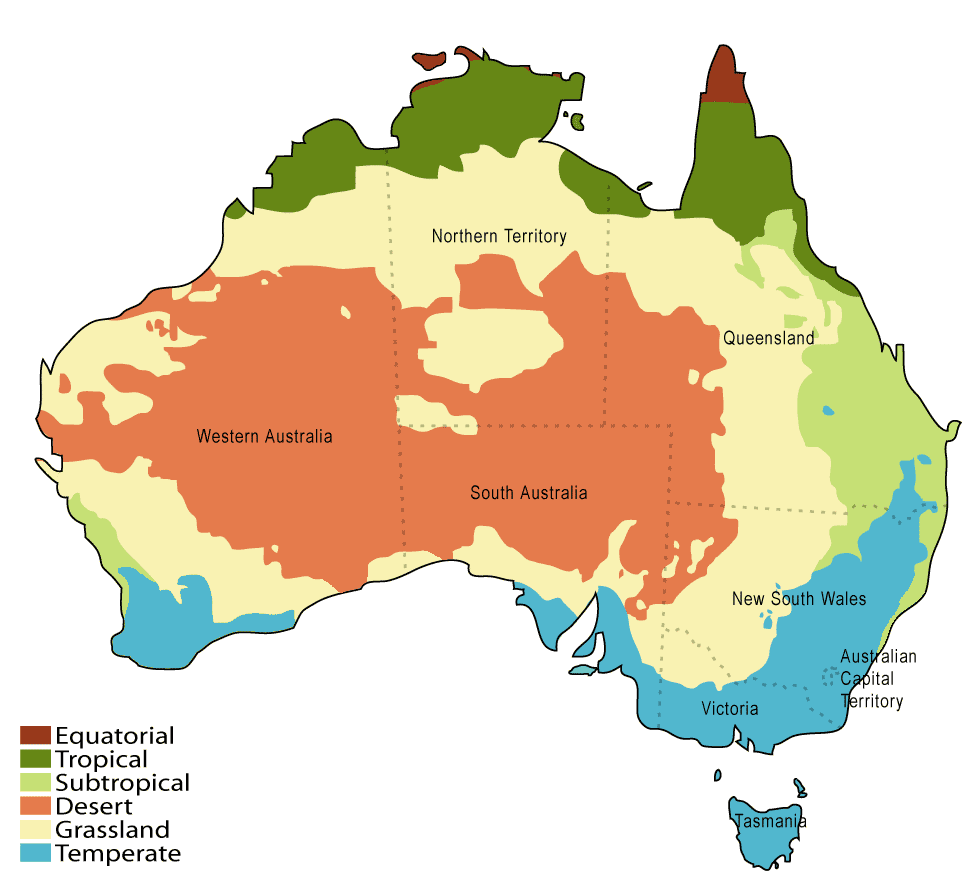

Agrupamos las 49 estaciones en 7 regiones climáticas según los criterios del BOM. Así la ubicación entra al modelo como 6 variables dummy (one-hot, con `Desértica` como categoría de referencia) en lugar de 48, y estaciones con climas parecidos comparten la misma información.

In [16]:
regiones_climaticas = {
    'Tropical': {
        # Región caracterizada por altas temperaturas todo el año, lluvias intensas en verano y ciclones.
        'Cairns':           (-16.9186, 145.7781),
        'Darwin':           (-12.4634, 130.8456),
        'Katherine':        (-14.4651, 132.2635),
        'Townsville':       (-19.2589, 146.8169)
    },

    'Subtropical': { # (Costa Este)
        # Humedad elevada, veranos cálidos con precipitaciones y estabilidad térmica invernal.
        'Brisbane':         (-27.4698, 153.0251),
        'CoffsHarbour':     (-30.2963, 153.1135),
        'GoldCoast':        (-28.0167, 153.4000),
        'NorfolkIsland':    (-29.0408, 167.9547)  # Territorio marítimo subtropical
    },

    'Desértica': { # (Centro)
        # Precipitaciones ínfimas (<250mm anuales), amplitudes térmicas extremas día/noche.
        'AliceSprings':     (-23.6980, 133.8807),
        'Uluru':            (-25.3444, 131.0369),
        'Woomera':          (-31.1997, 136.8253)
    },

    'Pastizales': { # (Estepa de Transición)
        # Clima seco que rodea los desiertos; alta variabilidad y propenso a sequías estacionales.
        'Cobar':            (-31.4980, 145.8347),
        'Mildura':          (-34.2080, 142.1246),
        'Moree':            (-29.4640, 149.8344),
        'Nhil':             (-36.3328, 141.6503),
        'SalmonGums':       (-32.9815, 121.6438)
    },

    'Templada': { # (Costa Sur y Sureste)
        # Cuatro estaciones bien marcadas. Veranos templados/cálidos e inviernos frescos. Concentra la mayoría de las estaciones.
        'Adelaide':         (-34.9285, 138.6007),
        'Albury':           (-36.0737, 146.9135),
        'BadgerysCreek':    (-33.8830, 150.7717),
        'Ballarat':         (-37.5622, 143.8503),
        'Bendigo':          (-36.7570, 144.2794),
        'Canberra':         (-35.2809, 149.1300),
        'Dartmoor':         (-37.9220, 141.2760),
        'Hobart':           (-42.8821, 147.3272),
        'Launceston':       (-41.4332, 147.1441),
        'Melbourne':        (-37.8136, 144.9631),
        'MelbourneAirport': (-37.6733, 144.8433),
        'Newcastle':        (-32.9283, 151.7817),
        'NorahHead':        (-33.2833, 151.5667),
        'Nuriootpa':        (-34.4667, 138.9833),
        'Penrith':          (-33.7510, 150.6940),
        'Richmond':         (-33.5996, 150.7510),
        'Sale':             (-38.1051, 147.0658),
        'Sydney':           (-33.8688, 151.2093),
        'SydneyAirport':    (-33.9399, 151.1753),
        'Tuggeranong':      (-35.4156, 149.0888),
        'WaggaWagga':       (-35.1082, 147.3598),
        'Watsonia':         (-37.7110, 145.0830),
        'Williamtown':      (-32.8150, 151.8428),
        'Wollongong':       (-34.4278, 150.8931)
    },

    'Oceánica': { # (Sudoeste y Costa Sur Fría)
        # Inviernos muy lluviosos por frentes antárticos y veranos secos (típico del sudoeste de WA y franja sur costera).
        'Albany':           (-35.0269, 117.8837),
        'MountGambier':     (-37.8284, 140.7804),
        'PearceRAAF':       (-31.6676, 116.0292),
        'Perth':            (-31.9505, 115.8605),
        'PerthAirport':     (-31.9403, 115.9669),
        'Portland':         (-38.3457, 141.6042),
        'Walpole':          (-34.9777, 116.7338),
        'Witchcliffe':      (-34.0261, 115.1005)
    },

    'Montañoso': {
        # Microclima específico de alta montaña, temperaturas invernales bajo cero y precipitaciones en forma de nieve.
        'MountGinini':      (-35.5294, 148.7723)
    }
}

# Ciudad -> Región Climática.
mapeo_ciudad_region = {
    ciudad: region
    for region, ciudades in regiones_climaticas.items()
    for ciudad in ciudades
}

df['Region_BOM'] = df['Location'].map(mapeo_ciudad_region)

print(f'Distribución de observaciones por región BOM:')
print(df['Region_BOM'].value_counts())


Distribución de observaciones por región BOM:
Region_BOM
Templada       71743
Oceánica       23770
Pastizales     13368
Subtropical    12054
Tropical       10770
Desértica       7542
Montañoso       2906
Name: count, dtype: int64


In [17]:
dummies_region = pd.get_dummies(df['Region_BOM'], prefix='Region', drop_first=True, dtype=int)
df = df.join(dummies_region)

columnas_region = dummies_region.columns.tolist()
print('Columnas creadas:', columnas_region)


Columnas creadas: ['Region_Montañoso', 'Region_Oceánica', 'Region_Pastizales', 'Region_Subtropical', 'Region_Templada', 'Region_Tropical']


#### 1.1.4 Distribución de variables

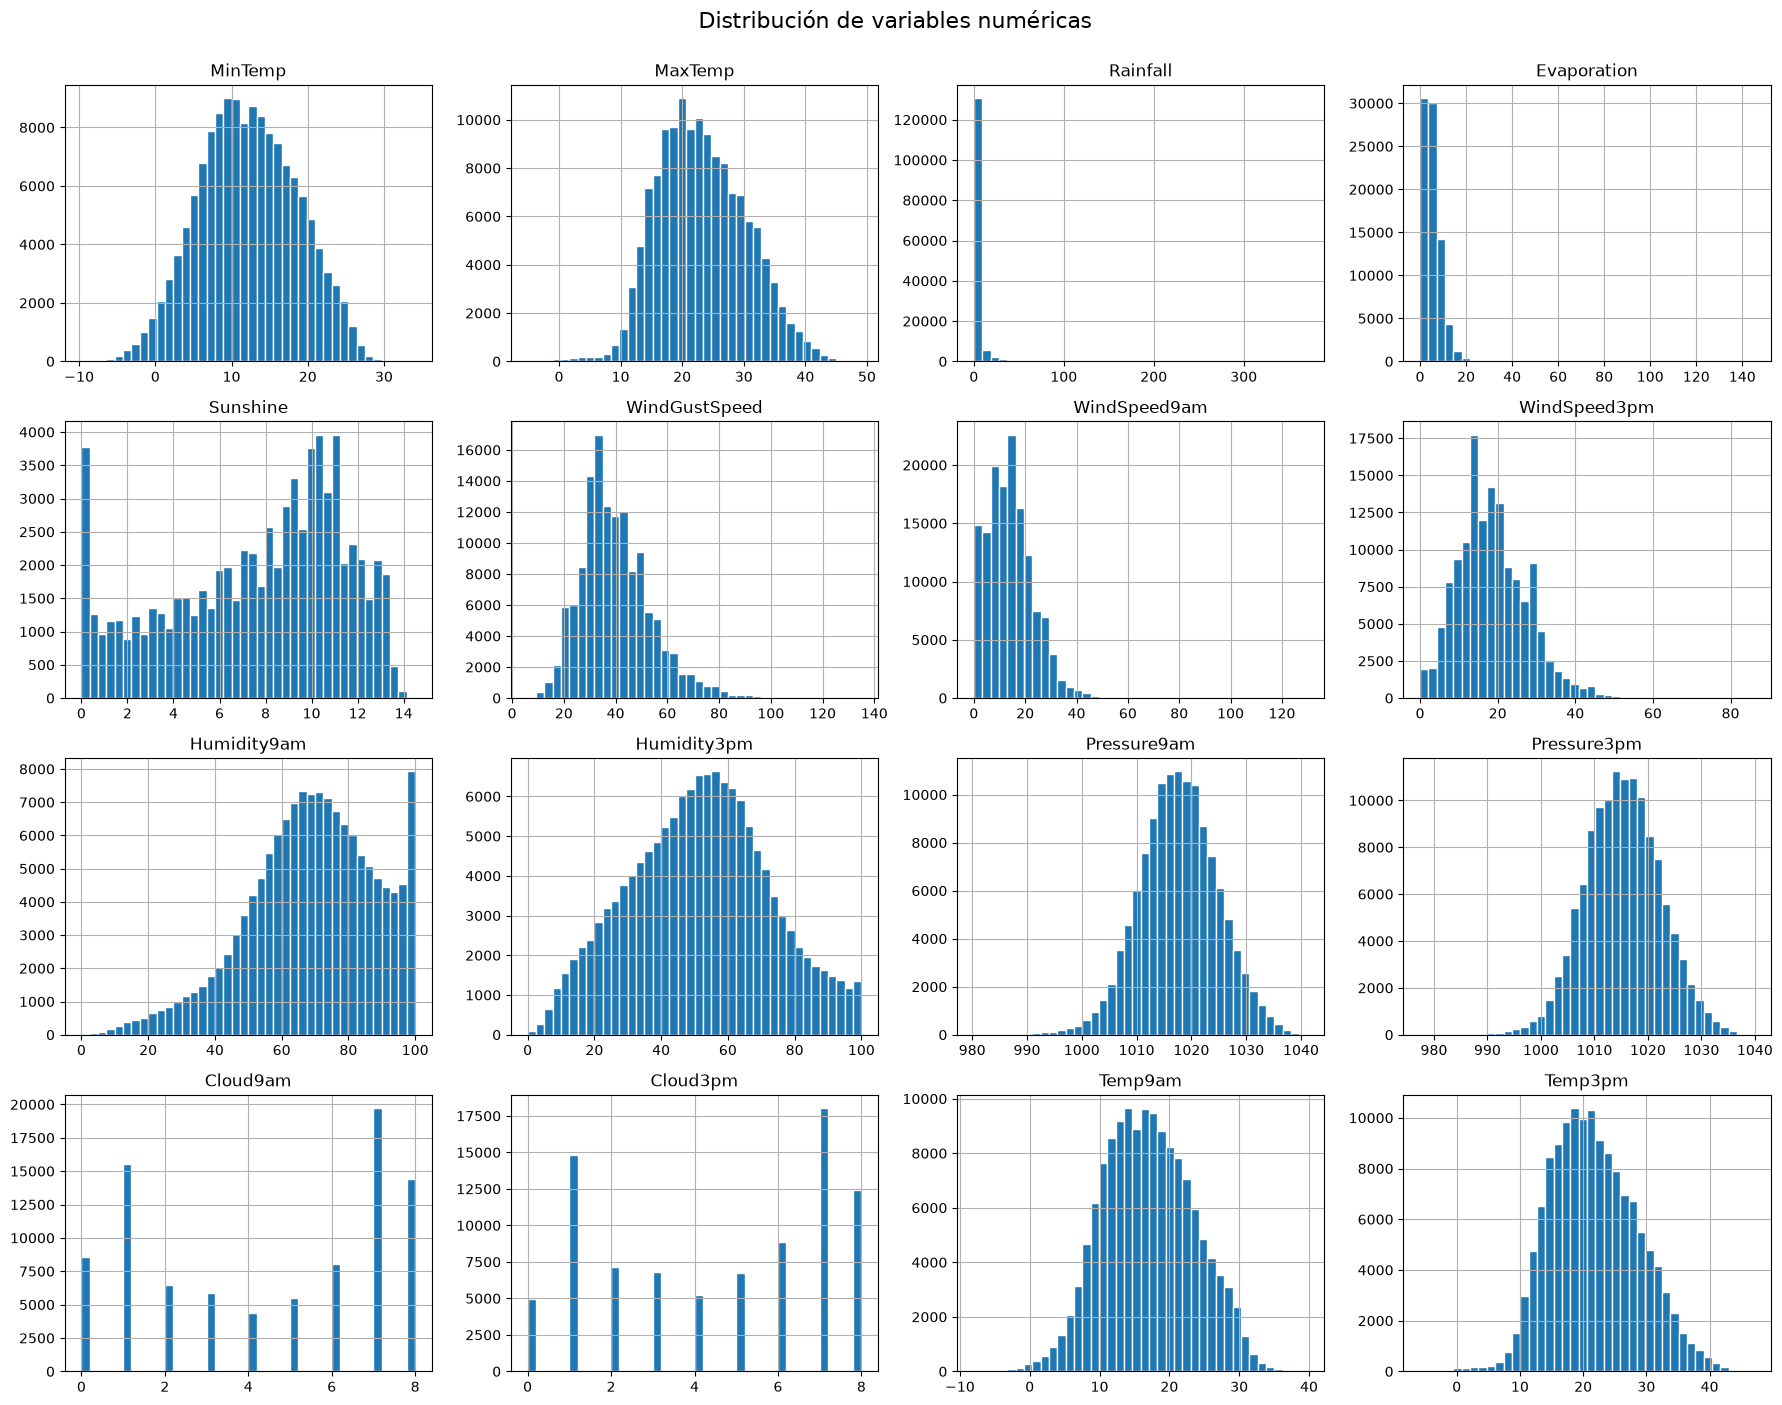

In [18]:
#Distribucion de variables numericas

columnas_numericas = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                      'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
                      'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm',
                      'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']

# Histogramas
df[columnas_numericas].hist(figsize=(18, 14), bins=40, edgecolor='white')
plt.suptitle('Distribución de variables numéricas', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

Descripción:
- `MinTemp`, `MaxTemp`: casi simétricas, pocos valores extremos.
- `Temp9am`, `Temp3pm`: casi simetricas
- `Rainfall`: Muy asimétrica, sesgo fuertemente positivo (la mayoria de los dias no llueve)
- `Evaporation`: Similar a rainfall pero menos concentrada
- `Sunshine`: Bimodal, si no se consideran los dias con muy pocas horas de sol, tiene sesgo negativo
- `WindGustSpeed`, `WindSpeed9am`, `WindSpeed3pm`: Sesgo positivo, se observan vientos mas fuertes por la mañana que por la tarde
- `Humidity9am`, `Humidity3pm`: A la mañana hay casos en los que el valor alcanza el 100%, sin considerar esos casos, la distribución es casi simétrica. Por la tarde la distribución tiene una simetría mas pronunciada.
-  `Pressure9am`, `Pressure3pm`: Simetricas, por la tarde la presión suele ser levemente menor.
-  `Cloud9am`, `Cloud3pm`: Discretas y bimodales. Los valores mas frecuentes son 1 y 7 (casi extremos).


Diagramas de caja

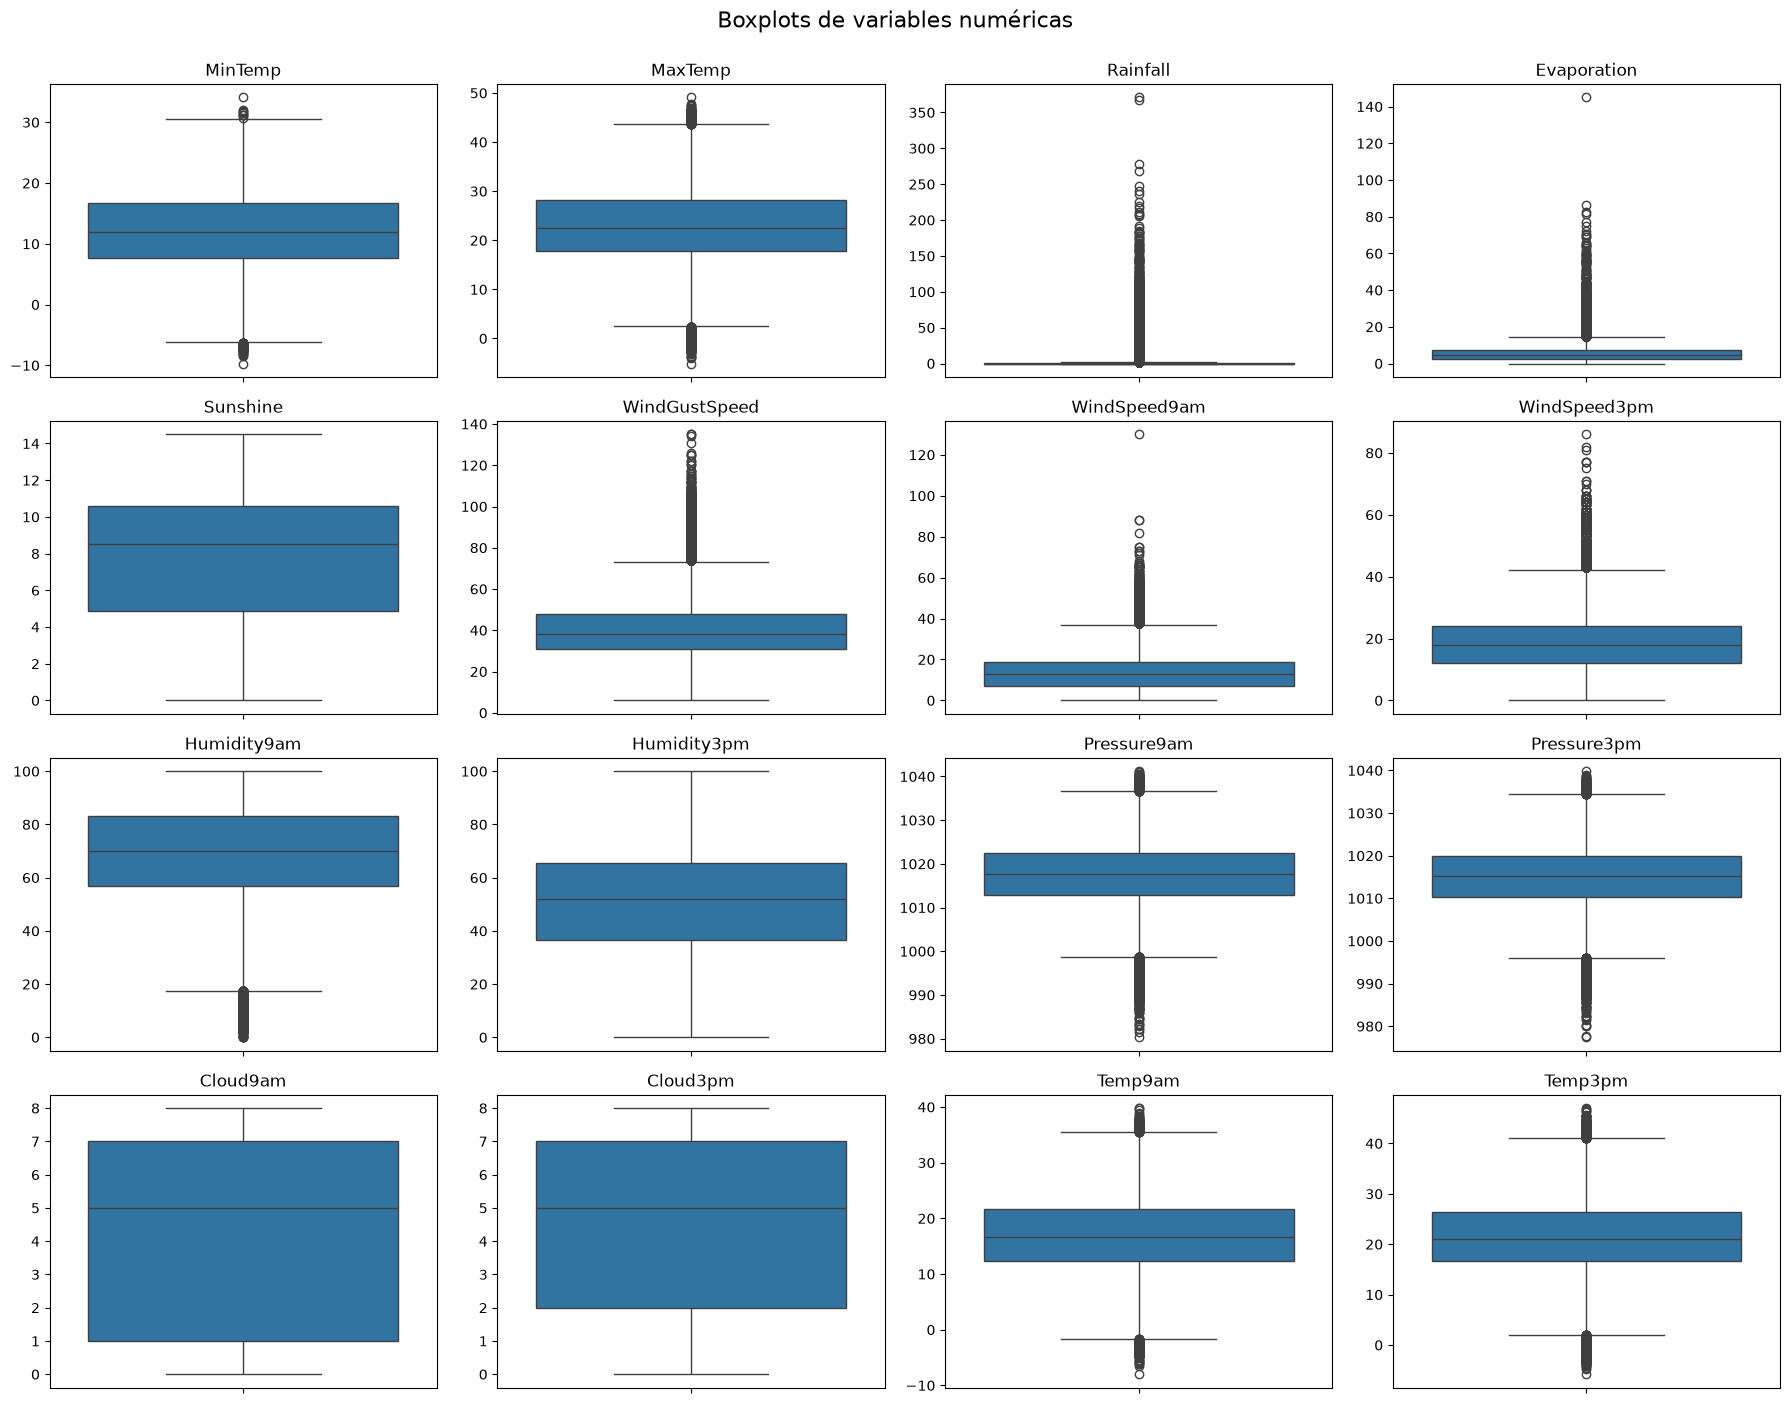

In [19]:
# Boxplots de todas las variables numéricas
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('')

plt.suptitle('Boxplots de variables numéricas', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

Observaciones:

- `Rainfall`, `WindGustSpeed` y `Evaporation` son las variables con más valores atípicos. 
- En las temperaturas, la humedad y la presión los valores extremos son pocos.

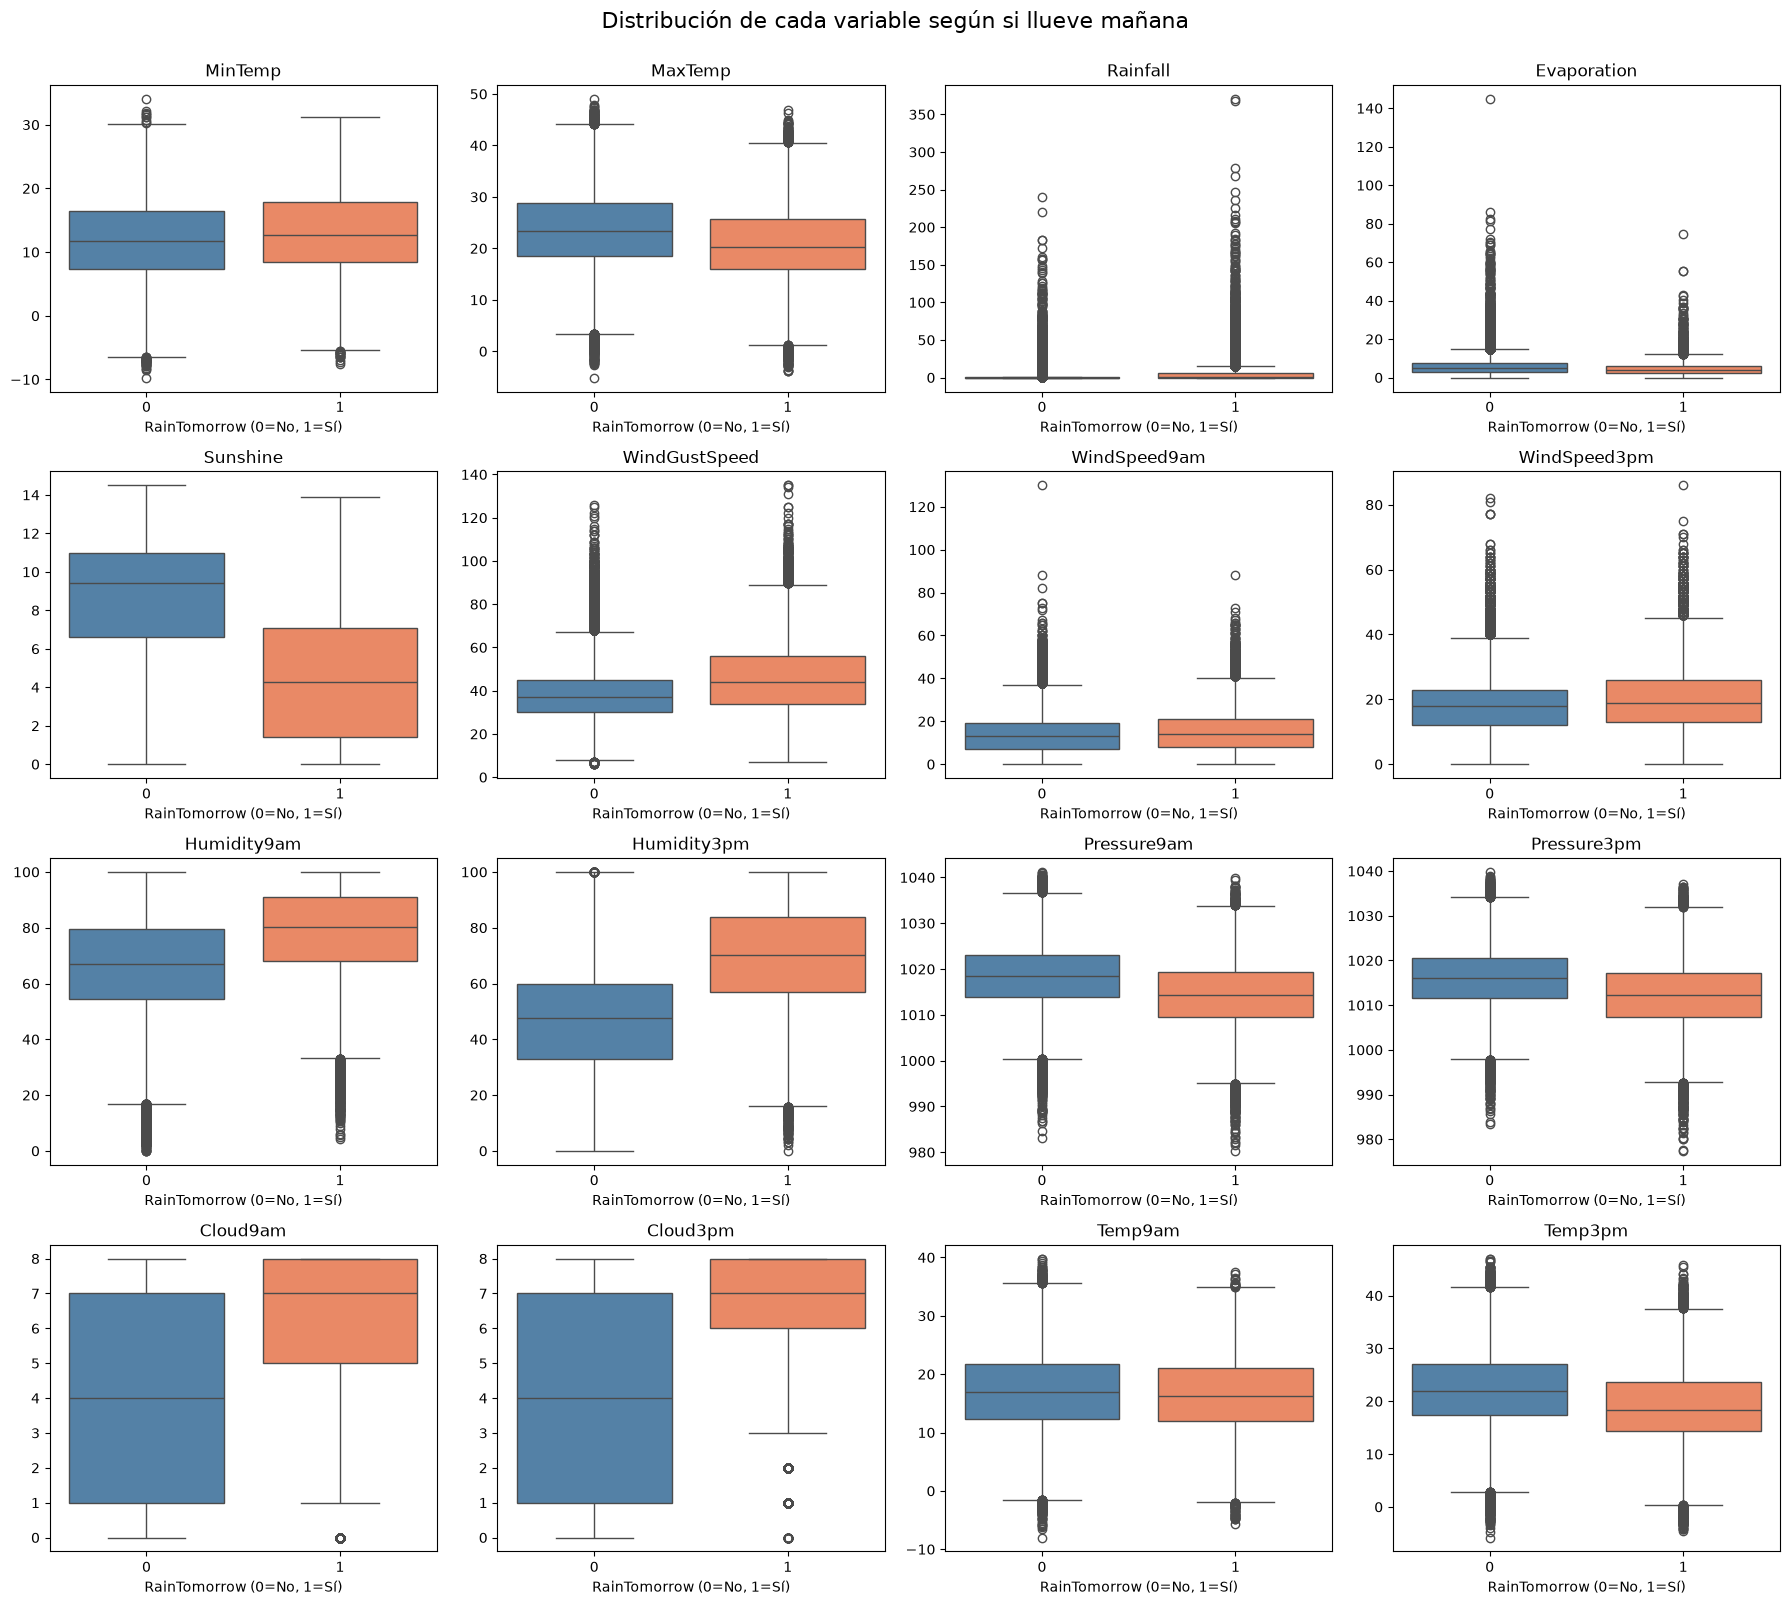

In [20]:
# Boxplots de cada variable numérica segmentados por RainTomorrow
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    sns.boxplot(
        data=df,
        x='RainTomorrow',
        y=col,
        ax=axes[i],
        hue='RainTomorrow',
        palette={0: 'steelblue', 1: 'coral'},
        legend=False
    )
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('RainTomorrow (0=No, 1=Sí)')
    axes[i].set_ylabel('')

plt.suptitle('Distribución de cada variable según si llueve mañana',
             fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

Las variables que más cambian respecto a `RainTomorrow` son:
- `Humidity3pm`
- `Cloud9am` y `Cloud3pm`
- `Sunshine`
- `Pressure9am` y `Pressure3pm`

*Antes de un día de lluvia el aire está más húmedo, el cielo más cubierto y la presión más baja. Además, suele estar menos tiempo soleado.*

Diagrama de dispersión

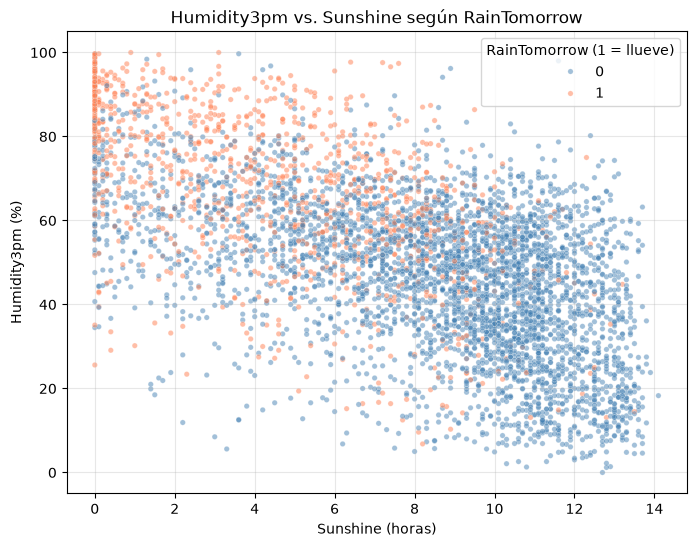

In [21]:
# Humedad a las 3 pm contra horas de sol según si llueve mañana (muestra de 5000 días para que se vean los puntos)
muestra = df.dropna(subset=['Humidity3pm', 'Sunshine']).sample(5000, random_state=SEMILLA)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=muestra, x='Sunshine', y='Humidity3pm', hue='RainTomorrow',
                palette={0: 'steelblue', 1: 'coral'}, alpha=0.5, s=15)
plt.title('Humidity3pm vs. Sunshine según RainTomorrow')
plt.xlabel('Sunshine (horas)')
plt.ylabel('Humidity3pm (%)')
plt.legend(title='RainTomorrow (1 = llueve)')
plt.grid(alpha=0.3)
plt.show()

Los días previos a lluvia (en coral) se concentran arriba a la izquierda: humedad alta y pocas horas de sol. Los días sin lluvia al día siguiente se ubican sobre todo abajo a la derecha. Hay una zona amplia donde las dos clases se superponen, así que ninguna de estas variables alcanza sola para separar los días. En esa zona es donde después el modelo comete los falsos positivos y falsos negativos.

#### 1.1.5 Balance de clases

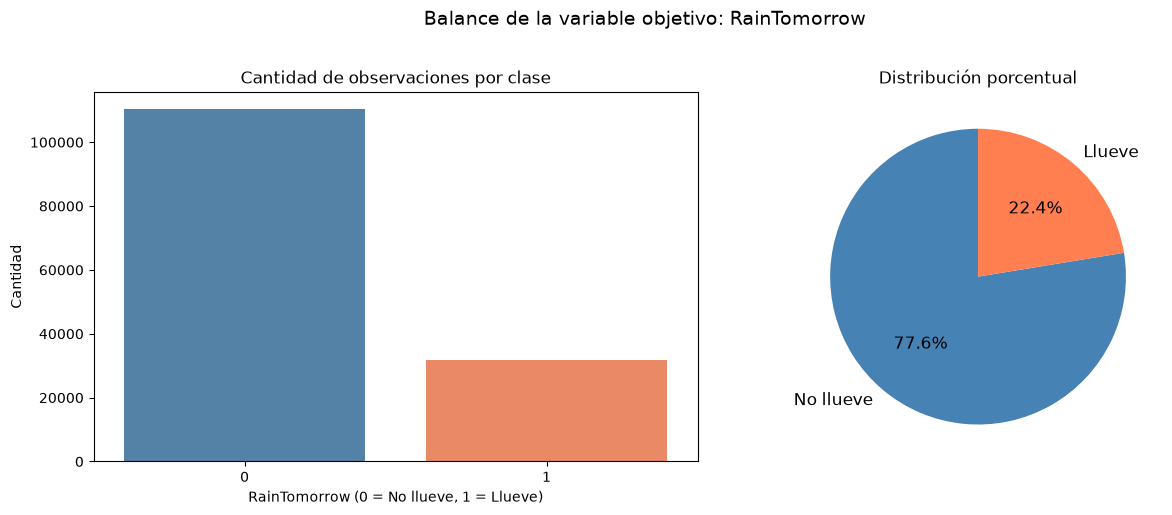

In [22]:
# Distribución de la variable objetivo
counts = df['RainTomorrow'].value_counts()
porcentajes = df['RainTomorrow'].value_counts(normalize=True) * 100

# Visualización del desbalance
fig, axes = plt.subplots(1, 2, figsize=(13, 5))


sns.countplot(x=df['RainTomorrow'], ax=axes[0],
              hue=df['RainTomorrow'],
              palette={0: 'steelblue', 1: 'coral'},
              legend=False)
axes[0].set_title('Cantidad de observaciones por clase')
axes[0].set_xlabel('RainTomorrow (0 = No llueve, 1 = Llueve)')
axes[0].set_ylabel('Cantidad')

axes[1].pie(counts,
            labels=['No llueve', 'Llueve'],
            colors=['steelblue', 'coral'],
            autopct='%1.1f%%',
            startangle=90,
            textprops={'fontsize': 12})
axes[1].set_title('Distribución porcentual')

plt.suptitle('Balance de la variable objetivo: RainTomorrow', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

El dataset está desbalanceado: 
- 77.6% de los días no llueve al día siguiente (110281 días)
- 22.4% de los días sí llueve al día siguiente (31872 días)

Ésto condiciona cómo entrenar y evaluar el modelo:
- Un modelo que siempre predice "no llueve" ya acierta el 77.6% de las veces (**accuracy** engañoso)
    - Hay que evaluar otras métricas como la **precision**, el **recall** y el **F1**.
- El modelo tiende a favorecer la clase mayoritaria y a detectar pocos días de lluvia. 
    - Se puede compensar dándole más peso a la clase minoritaria (`class_weight='balanced'`) 
    - O ajustando el umbral de decisión

#### 1.1.6 Valores faltantes

In [23]:
# Valores faltantes por variable
resumen = pd.DataFrame({
    'No_Nulos': df.notnull().sum(),
    'Nulos': df.isnull().sum(),
    '%_Nulos': (df.isnull().sum() / len(df) * 100).round(2),
    'Valores_Unicos': df.nunique()
})
resumen = resumen[resumen['Nulos'] > 0].sort_values('%_Nulos', ascending=False)
resumen

,No_Nulos,Nulos,%_Nulos,Valores_Unicos
Sunshine,74368,67785,47.68,145
Evaporation,81341,60812,42.78,356
Cloud3pm,85077,57076,40.15,9
Cloud9am,88512,53641,37.73,9
Pressure9am,128143,14010,9.86,547
Pressure3pm,128176,13977,9.83,542
WindDir9am,132144,10009,7.04,16
WindDir9am_sin,132144,10009,7.04,14
WindDir9am_cos,132144,10009,7.04,16
WindGustDir,132825,9328,6.56,16


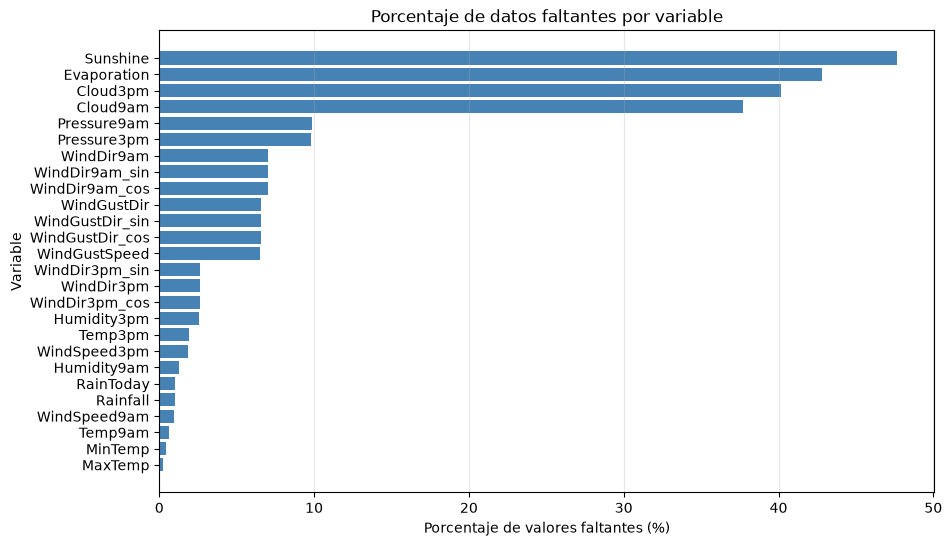

In [24]:
# Visualización de faltantes
plt.figure(figsize=(10, 6))
plt.barh(resumen.index, resumen['%_Nulos'], color='steelblue')
plt.xlabel('Porcentaje de valores faltantes (%)')
plt.ylabel('Variable')
plt.title('Porcentaje de datos faltantes por variable')
plt.gca().invert_yaxis()  # mayor arriba
plt.grid(True, alpha=0.3, axis='x')


Las variables con más datos faltantes son:
- `Sunshine` (>45%)
- `Evaporation`(>40%) 
- `Cloud3pm`,`Cloud9am` (>35%)

**Proporción de valores faltantes por variable y ciudad**

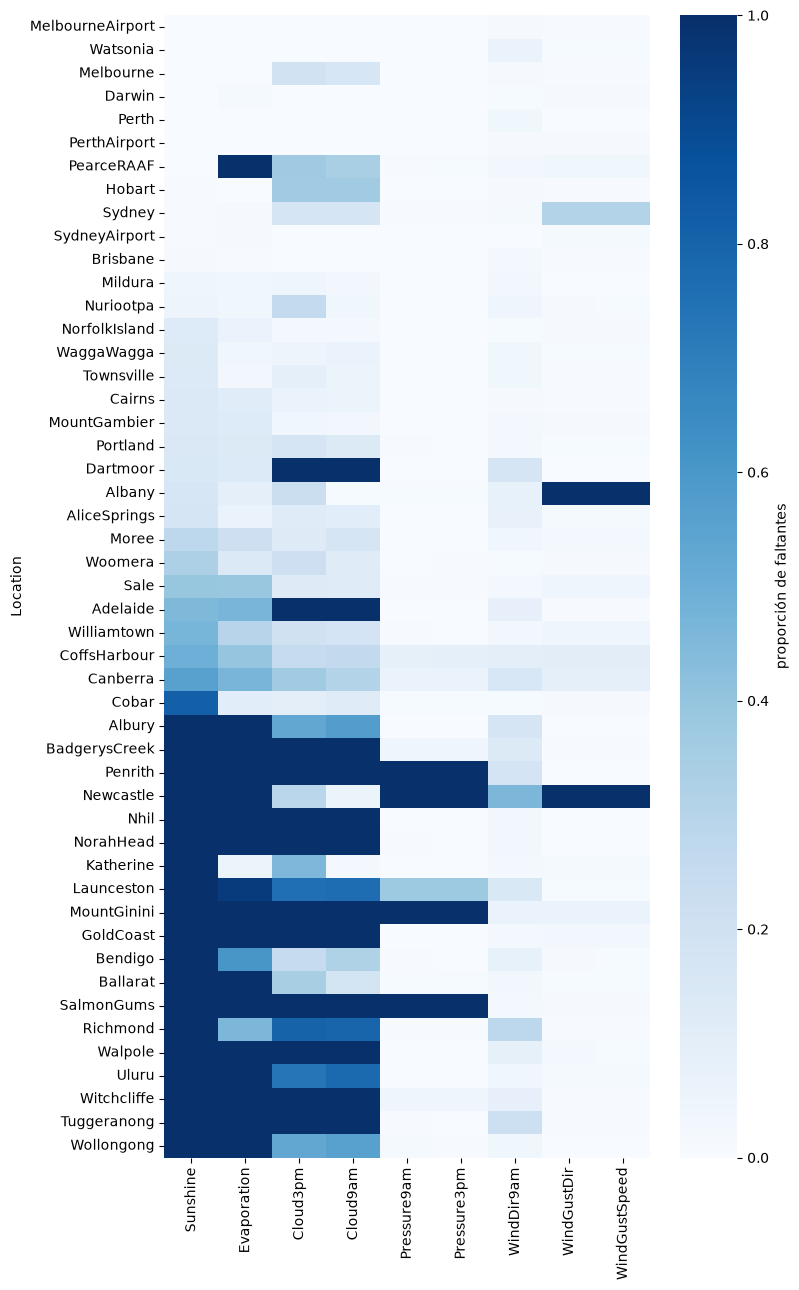

In [25]:
# Proporción de faltantes por ciudad para las variables más incompletas
cols_falt = ['Sunshine', 'Evaporation', 'Cloud3pm', 'Cloud9am', 'Pressure9am', 'Pressure3pm','WindDir9am', 'WindGustDir', 'WindGustSpeed']
falt_ciudad = df.groupby('Location')[cols_falt].apply(lambda g: g.isna().mean())
fig, ax = plt.subplots(figsize=(8, 13))
sns.heatmap(falt_ciudad.sort_values('Sunshine'), cmap='Blues', vmin=0, vmax=1,
            cbar_kws={'label': 'proporción de faltantes'}, ax=ax)
plt.tight_layout()
plt.show()

En las variables con más valores faltantes, los nulos se concentran en estaciones que directamente no miden esa variable:
- 19 estaciones no tienen ningún dato de `Sunshine`
- 16 de `Evaporation`
- 12 de nubosidad
- 4 de presión. 

*Es decir, muchos de los faltantes no aparecen al azar. Conservaremos todos los registros para no modificar  la distribución de información respecto a los distintos lugares de medición*

**Relación entre los faltantes y la variable objetivo**

In [26]:
# Porcentaje de días previos a lluvia según si falta o no cada variable
cols_falt_objetivo = cols_falt + ['Rainfall']
falta_vs_objetivo = pd.DataFrame({
    '% lluvia mañana (con dato)': [df.loc[df[c].notna(), 'RainTomorrow'].mean() * 100 for c in cols_falt_objetivo],
    '% lluvia mañana (sin dato)': [df.loc[df[c].isna(), 'RainTomorrow'].mean() * 100 for c in cols_falt_objetivo],
}, index=cols_falt_objetivo)

print('Filas con al menos un faltante:', f"{df[columnas_numericas + ['RainToday']].isna().any(axis=1).mean():.1%}")
falta_vs_objetivo.round(1)

Filas con al menos un faltante: 59.1%


,% lluvia mañana (con dato),% lluvia mañana (sin dato)
Sunshine,22.6,22.2
Evaporation,22.0,23.0
Cloud3pm,23.8,20.3
Cloud9am,23.3,21.0
Pressure9am,22.5,22.1
Pressure3pm,22.4,22.3
WindDir9am,22.7,19.2
WindGustDir,22.1,26.4
WindGustSpeed,22.1,26.3
Rainfall,22.2,48.1


Decisión sobre los datos faltantes:
- Eliminamos solo las filas sin `RainTomorrow` (2.2%), porque sin la variable objetivo no sirven para entrenar ni para evaluar.
- No eliminamos filas por faltantes en las demás variables: el 59% de las filas tiene al menos un faltante, así que perderíamos la mayor parte de los datos y estaciones enteras.
- No descartamos `Sunshine`, `Evaporation`, `Cloud3pm` ni `Cloud9am` aunque les falte más del 35% de los datos: `Sunshine` y `Cloud3pm` están entre las variables más correlacionadas con `RainTomorrow`

- Imputamos después de dividir los datos, con parámetros calculados solo en train. 

- En casi todas las variables, que falte el dato no cambia la proporción de días previos a lluvia. 
    - La excepción es `Rainfall` (48% contra 22%), pero falta solo en el 1% de los días.


Usaremos `IterativeImputer`, que estima cada variable a partir de las demás del mismo día (por ejemplo, `Sunshine` a partir de la nubosidad y la humedad) y de la época del año. Las direcciones del viento faltantes se completan con reglas (por ejemplo, si no hubo viento).

#### 1.1.7 Regiones y climogramas

Climograma para las distintas regiones

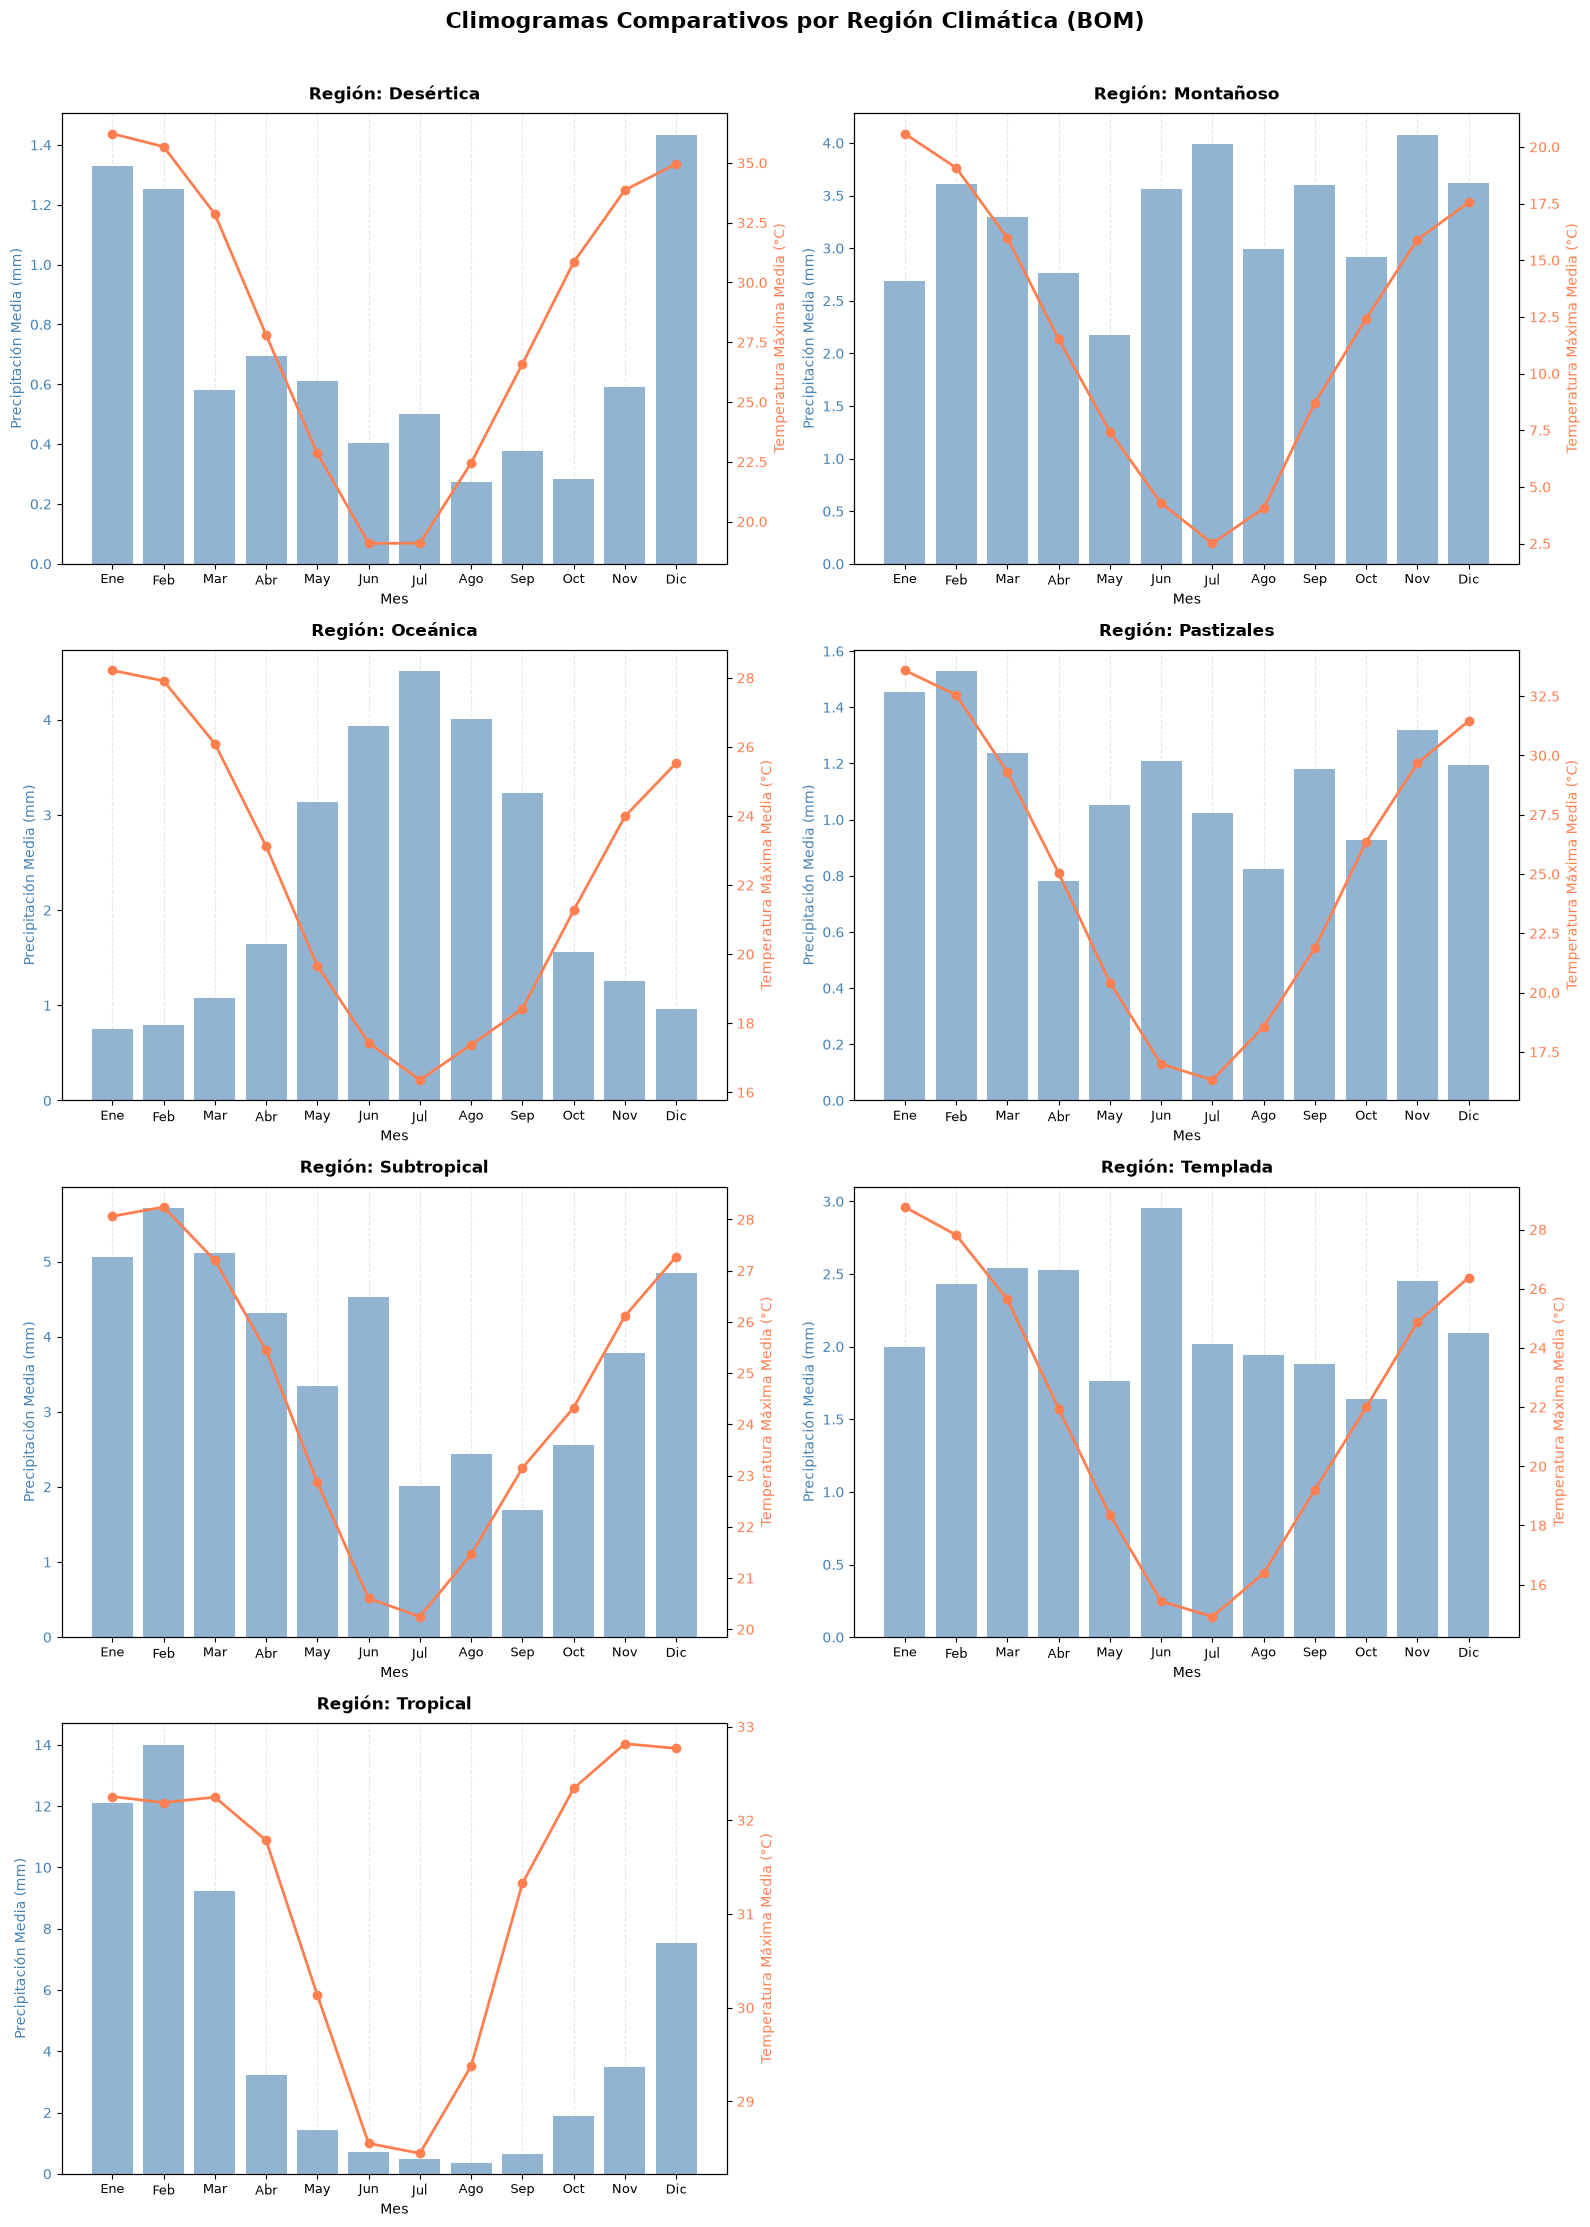

In [27]:
# Se agrupa los datos por Región y por Mes para calcular las medias correspondientes
monthly_data = df.groupby(['Region_BOM', 'Month']).agg({'MaxTemp': 'mean', 'Rainfall': 'mean'}).reset_index()

regiones = monthly_data['Region_BOM'].dropna().unique()
num_regiones = len(regiones)

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 22), sharex=False)
axes = axes.flatten()

color_rain = 'steelblue'
color_temp = 'coral'

# Construcción del climograma para cada región climática
for i, region in enumerate(regiones):
    ax1 = axes[i]

    data_region = monthly_data[monthly_data['Region_BOM'] == region].sort_values('Month')

    # Eje Izquierdo: Precipitación 
    ax1.bar(data_region['Month'], data_region['Rainfall'], color=color_rain, alpha=0.6, label='Precipitación')
    ax1.set_ylabel('Precipitación Media (mm)', color=color_rain, fontsize=10)
    ax1.tick_params(axis='y', labelcolor=color_rain)
    ax1.set_xticks(range(1, 13))
    ax1.set_xticklabels(['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'], fontsize=9)
    ax1.set_xlabel('Mes', fontsize=10)

    # Eje Derecho: Temperatura Máxima 
    ax2 = ax1.twinx()
    ax2.plot(data_region['Month'], data_region['MaxTemp'], color=color_temp, marker='o', linewidth=2, label='Temp Máx')
    ax2.set_ylabel('Temperatura Máxima Media (°C)', color=color_temp, fontsize=10)
    ax2.tick_params(axis='y', labelcolor=color_temp)

    # Personalización estética de cada panel
    ax1.set_title(f'Región: {region}', fontsize=12, fontweight='bold', pad=10)
    ax1.grid(True, linestyle='--', alpha=0.3, axis='x')

for j in range(num_regiones, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Climogramas Comparativos por Región Climática (BOM)', fontsize=16, fontweight='bold', y=1.01)
fig.tight_layout()
plt.show()

Pueden observarse variación en los regímenes de lluvia y temperaturas segun la region:
- Desértica: muy poca lluvia y veranos muy calurosos.
- Montañoso: la región más fría y lluvia frecuente todo el año.
- Oceánica: lluvia de invierno y veranos sin lluvia.
- Pastizales: lluvia uniforme pero baja en el año y altas temperaturas
- Subtropical: llueve todo el año, más en verano y otoño.
- Templada: lluvia todo el año
- Tropical: lluvias en verano  y casi nulas en invierno, temperaturas altas todo el año.



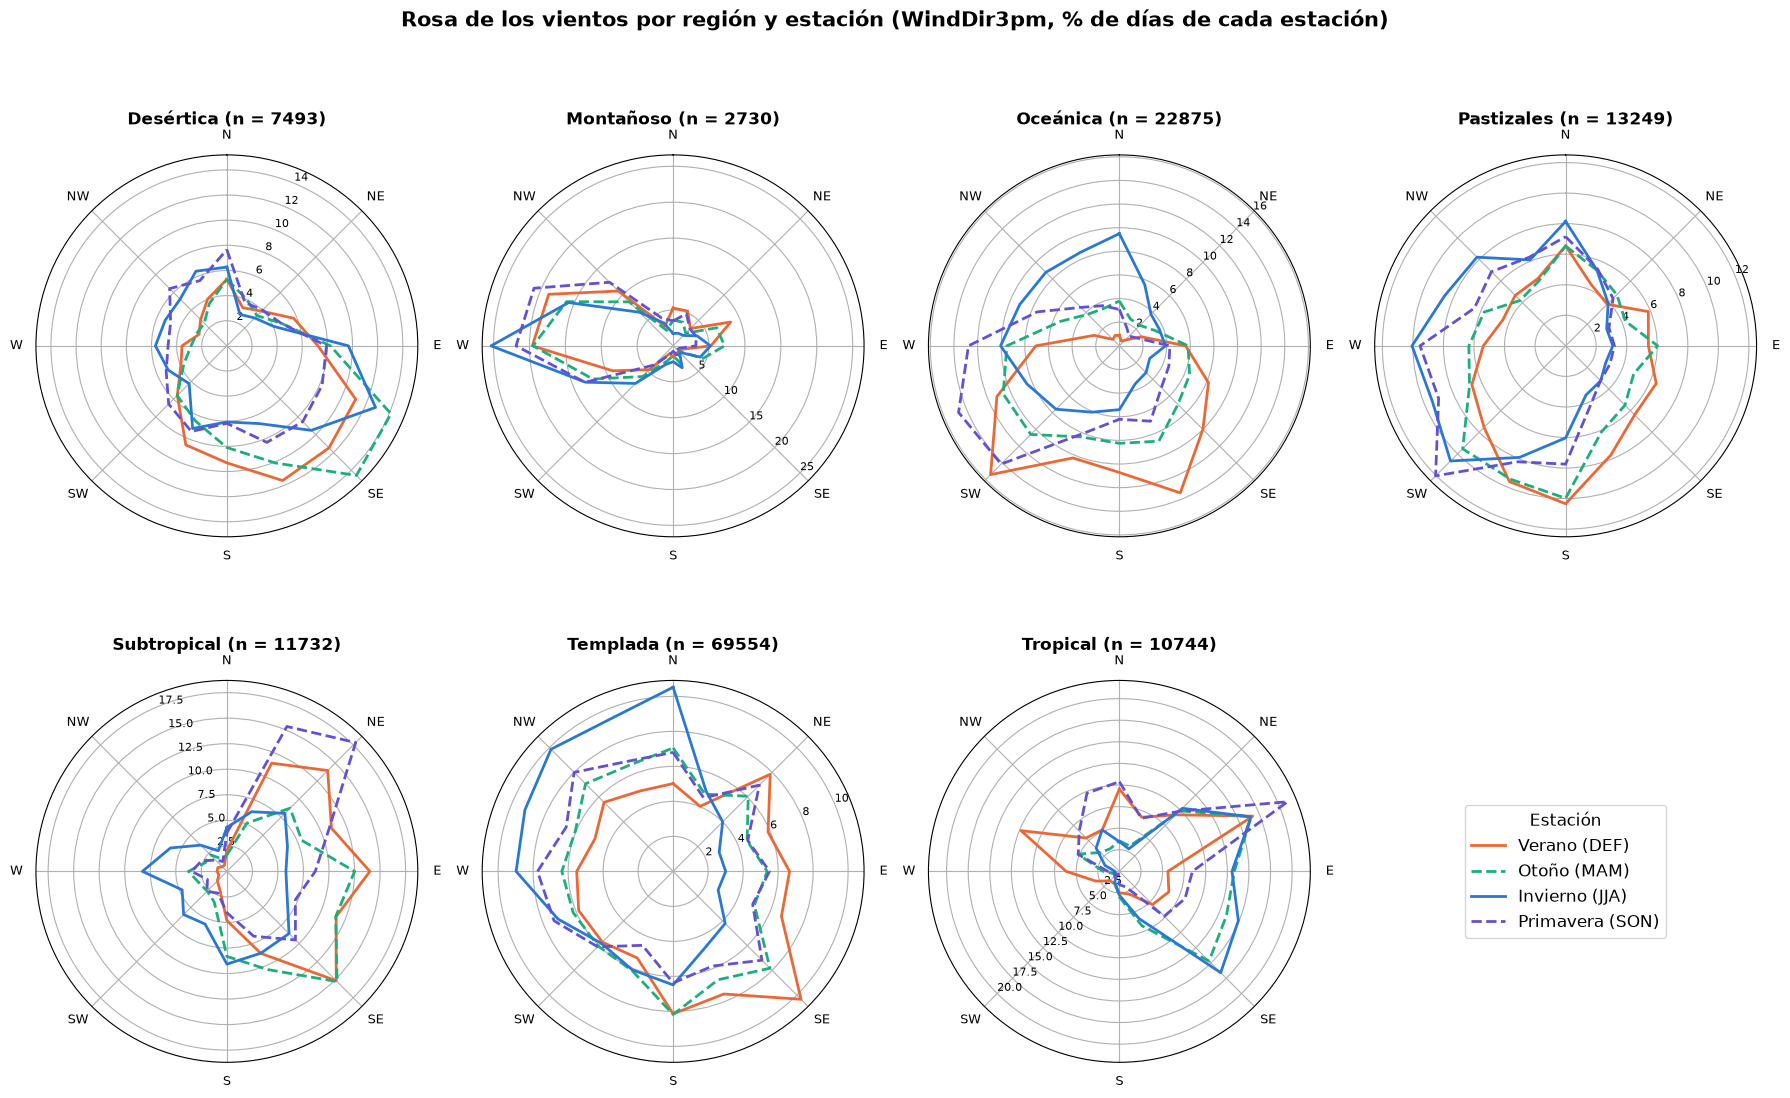

In [28]:
# Rosa de los vientos por región: % de días según la dirección del viento a las 15 h (WindDir3pm) en cada estación
estaciones = {'Verano (DEF)': [12, 1, 2], 'Otoño (MAM)': [3, 4, 5],
              'Invierno (JJA)': [6, 7, 8], 'Primavera (SON)': [9, 10, 11]}
estilo_estacion = {'Verano (DEF)': ('#eb6834', '-'), 'Otoño (MAM)': ('#1baf7a', '--'),
                   'Invierno (JJA)': ('#2a78d6', '-'), 'Primavera (SON)': ('#6250d6', '--')}
direcciones = list(direccion_a_grados.keys())
angulos = np.deg2rad(list(direccion_a_grados.values()))
angulos_cerrados = np.append(angulos, angulos[0])  # se repite el primer ángulo para cerrar la línea

viento = df.dropna(subset=['WindDir3pm', 'Region_BOM'])
regiones = sorted(viento['Region_BOM'].unique())

fig, axes = plt.subplots(2, 4, figsize=(18, 11.5), subplot_kw={'projection': 'polar'})
axes = axes.flatten()
for ax, region in zip(axes, regiones):
    datos_region = viento[viento['Region_BOM'] == region]
    total = np.zeros(len(direcciones))
    for estacion, meses_estacion in estaciones.items():
        datos_estacion = datos_region[datos_region['Month'].isin(meses_estacion)]
        porcentajes = datos_estacion['WindDir3pm'].value_counts(normalize=True).reindex(direcciones, fill_value=0).values * 100
        color, linea = estilo_estacion[estacion]
        ax.plot(angulos_cerrados, np.append(porcentajes, porcentajes[0]), color=color, linestyle=linea, linewidth=2, label=estacion)
        total += porcentajes
    ax.set_theta_zero_location('N')  # norte arriba
    ax.set_theta_direction(-1)       # sentido horario, como una brújula
    ax.set_xticks(angulos[::2])
    ax.set_xticklabels(direcciones[::2], fontsize=9)
    ax.set_rlabel_position(np.rad2deg(angulos[np.argmin(total)]))  # etiquetas de % en la dirección con menos viento
    ax.tick_params(axis='y', labelsize=8)
    ax.set_title(f'{region} (n = {len(datos_region)})', fontsize=12, fontweight='bold', pad=22)

# Leyenda
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].axis('off')
axes[-1].legend(handles, labels, loc='center', title='Estación', fontsize=12, title_fontsize=12)

fig.suptitle('Rosa de los vientos por región y estación (WindDir3pm, % de días de cada estación)', fontsize=15, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.95], h_pad=4)
plt.show()

La intensidad y dirección de los vientos predominantes varían según la región climática:
- En la region desértica los vientos más comunes se encuentran concentrados entre la dirección Este y Sudeste
- En la región montañosa predominan fuertes vientos en dirección Oeste durante todo el año.
- En la región oceanica los vientos son dispersos pero mas intensos en direccioes Sudoeste y Sudeste.
- En la región pastizales los vientos

*La distribución de lluvias y dirección e intensidad de los variables según la región climática justifican su inclusión como variable del modelo.*

#### 1.1.8 Análisis de correlación

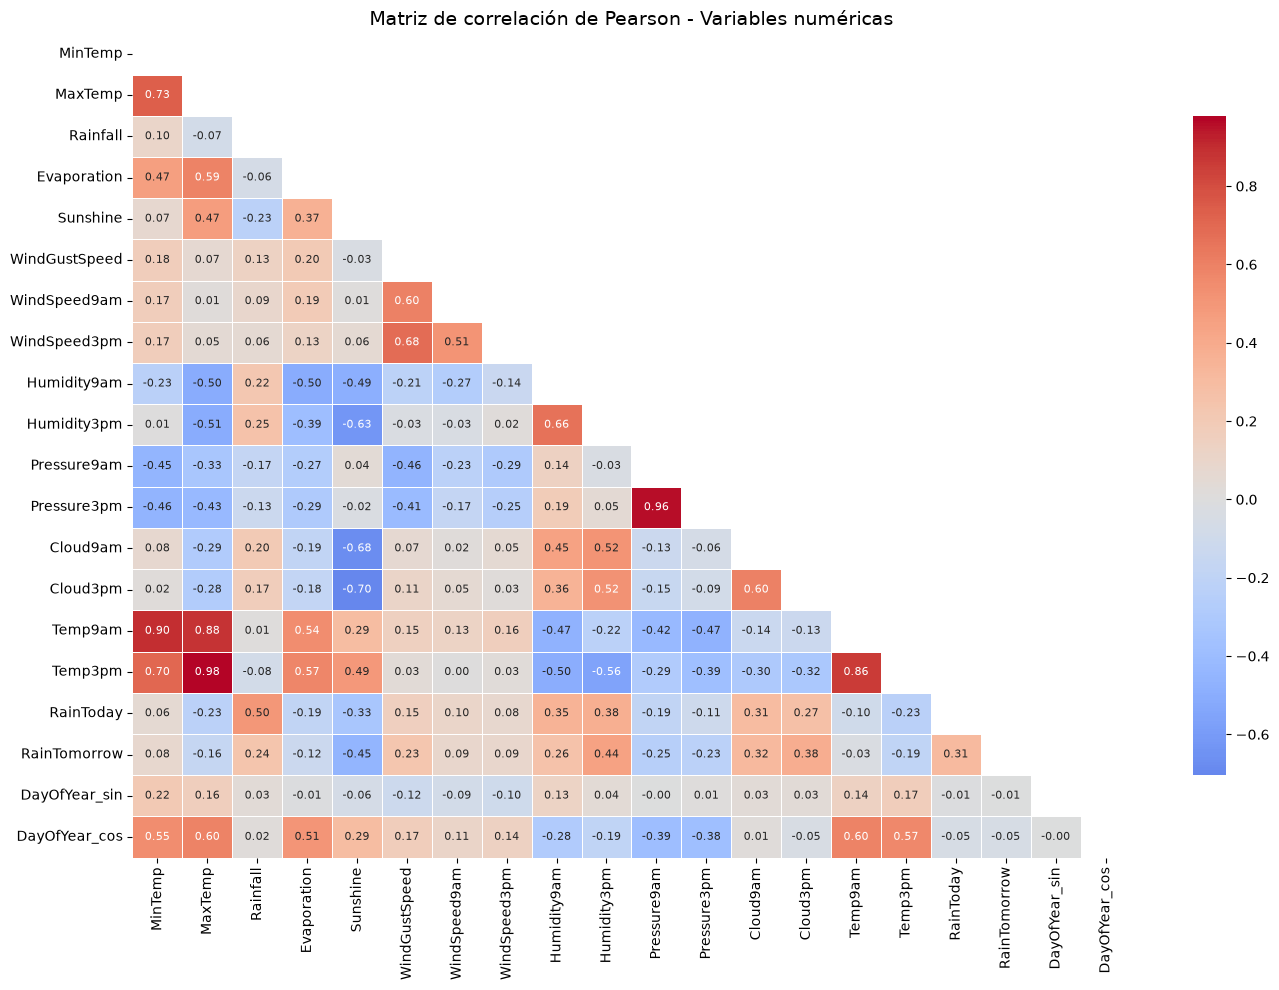

In [29]:
# Seleccionamos las variables numéricas para la matriz de correlación
columnas_correlacion = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                        'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
                        'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm',
                        'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm',
                        'RainToday', 'RainTomorrow',
                        'DayOfYear_sin', 'DayOfYear_cos']

# Calculamos correlación de Pearson
corr_matrix = df[columnas_correlacion].corr(method='pearson')

# Heatmap completo
plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # triángulo superior oculto
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0,
            annot=True, fmt='.2f', annot_kws={'size': 8},
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlación de Pearson - Variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

Hay pares de variables muy correlacionadas (medidas similares):
- `MaxTemp` y `Temp3pm` (0.98), `MinTemp` y `Temp9am` (0.90), y en general todas las temperaturas entre sí.
- `Pressure9am` y `Pressure3pm` (0.96).
- `Sunshine` y `Cloud3pm` (−0.70): mientras mas nubes, menos horas de sol.
- `Humidity9am` y `Humidity3pm` (0.66).

La alta correlación entre variables regresoras genera multicolinealidad. 

Sin embargo, `LogisticRegression` usa por defecto regularización L2 (Ridge Regression) atenuando el problema, así que mantenemos todas las variables.

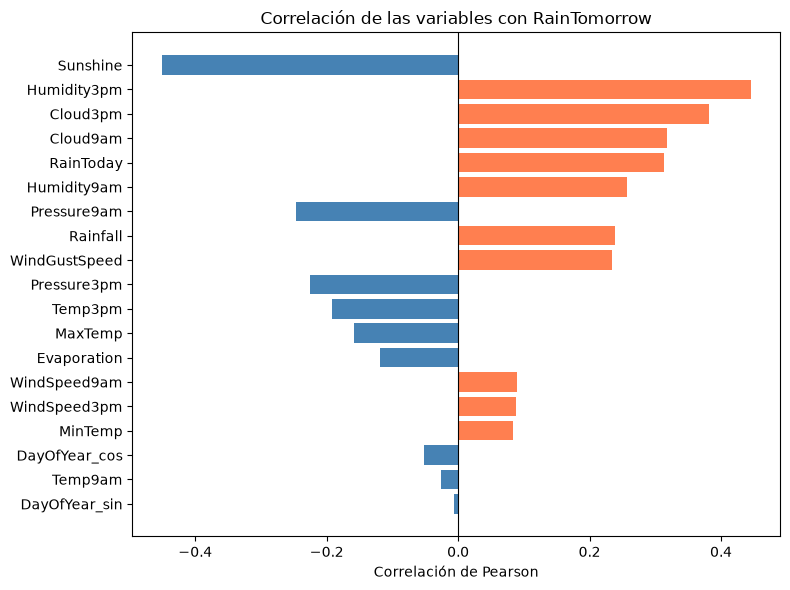

In [30]:
# Correlación de cada variable con RainTomorrow, ordenada por valor absoluto (coral: positiva, azul: negativa)
corr_target = corr_matrix['RainTomorrow'].drop('RainTomorrow')
corr_target = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index)

plt.figure(figsize=(8, 6))
plt.barh(corr_target.index[::-1], corr_target.values[::-1],
         color=['coral' if v > 0 else 'steelblue' for v in corr_target.values[::-1]])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlación de las variables con RainTomorrow')
plt.xlabel('Correlación de Pearson')
plt.ylabel('')
plt.tight_layout()
plt.show()

Las variables con mayor correlación (valor absoluto) respecto a `RainTomorrow`  son:
- `Sunshine`
- `Humidity3pm`
- `Cloud3pm`
- `Cloud9am` 
- `RainToday`

Esto consistente con los boxplots vistos previamente.

### 1.2 División en train, validación y test

In [31]:
# Variables del modelo: numéricas, RainToday, direcciones del viento y día del año (seno y coseno) y regiones (one-hot)
features = ['MinTemp', 'MaxTemp', 'Temp9am', 'Temp3pm',
            'Pressure9am', 'Pressure3pm',
            'Humidity9am', 'Humidity3pm',
            'Cloud9am', 'Cloud3pm',
            'RainToday', 'Rainfall',
            'Evaporation', 'Sunshine',
            'WindGustDir_sin', 'WindGustDir_cos',
            'WindDir9am_sin', 'WindDir9am_cos',
            'WindDir3pm_sin', 'WindDir3pm_cos',
            'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
            'DayOfYear_sin', 'DayOfYear_cos'] + columnas_region

X = df[features]
y = df['RainTomorrow']

Dividimos los datos antes de **imputar** y **escalar**. 

Todo lo que se calcula a partir de los datos (los parámetros del imputador y los del escalado) se obtiene de train, y el umbral de decisión se elige en validación.

Como los datos son una serie temporal, la división se hace con cortes en el tiempo: 
- train tiene los días más antiguos,
- validación tiene días posteriores a train 
- test tiene los días más recientes.

Además, cortamos en cambios de fecha, para que las observaciones de un mismo día (de estaciones que pueden estar bajo el mismo sistema meteorológico) no queden repartidas entre dos conjuntos.

Usamos aproximadamente el 70% de los datos para train, el 15% para validación y el 15% para test. 

**Validación sirve para analizar el modelo y elegir el umbral de decisión sin usar test.**

In [32]:
# Fechas de corte: las de los registros ubicados en el 70% y el 85% de los datos (ordenados por fecha)
fecha_corte_val = df['Date'].iloc[int(len(df) * 0.70)]
fecha_corte_test = df['Date'].iloc[int(len(df) * 0.85)]

# Cada fecha queda completa en un solo conjunto
en_train = df['Date'] < fecha_corte_val
en_val = (df['Date'] >= fecha_corte_val) & (df['Date'] < fecha_corte_test)
en_test = df['Date'] >= fecha_corte_test

X_train, y_train = X[en_train].copy(), y[en_train].copy()
X_val, y_val = X[en_val].copy(), y[en_val].copy()
X_test, y_test = X[en_test].copy(), y[en_test].copy()

In [33]:
# Rango de fechas, tamaño y proporción de días previos a lluvia de cada conjunto
resumen_split = pd.DataFrame({
    nombre: {'Desde': df.loc[y_conj.index, 'Date'].min().date(),
             'Hasta': df.loc[y_conj.index, 'Date'].max().date(),
             'Filas': len(y_conj),
             '% del total': round(len(y_conj) / len(df) * 100, 1),
             '% lluvia mañana': round(y_conj.mean() * 100, 1)}
    for nombre, y_conj in [('Train', y_train), ('Validación', y_val), ('Test', y_test)]
}).T
resumen_split

,Desde,Hasta,Filas,% del total,% lluvia mañana
Train,2007-11-01,2015-01-11,99499,70.0,22.6
Validación,2015-01-12,2016-04-06,21293,15.0,20.5
Test,2016-04-07,2017-06-24,21361,15.0,23.7


La proporción de días previos a lluvia cambia un poco entre conjuntos (22.6% en train, 20.5% en validación y 23.7% en test), porque cada uno cubre un período distinto. 

Esto explicará parte de las diferencias en las métricas entre validación y test.

### 1.3 Imputación de datos faltantes

La decisión sobre los faltantes se justifica en 1.1.6. Imputamos así:
- Variables numéricas: usamos `IterativeImputer`

    -  Estima cada variable con una regresión a partir de las demás y repite el proceso hasta que los valores imputados se estabilizan. 
    -   Es mejor que imputar con la mediana porque muchas variables están muy relacionadas entre sí, y en las estaciones que no miden una variable la mediana pondría el mismo valor todos los días. 

    - Incluimos `DayOfYear_sin` y `DayOfYear_cos` como predictores para que el imputador tenga en cuenta la época del año.

- Después recortamos los valores imputados al **rango físico** de cada variable, porque la regresión puede dar valores imposibles.

- Direcciones del viento: 
    - Si la velocidad del viento es 0 no hay dirección, y usamos el centro del círculo (seno y coseno iguales a 0). 
    - Si hubo viento, copiamos la dirección más parecida del mismo día (por ejemplo, la de la ráfaga para el viento de las 3 pm).
    - Si faltan las tres direcciones, usamos el centro del círculo.

- `RainToday`: la calculamos a partir de `Rainfall` imputada, con la misma definición del dataset (más de 1 mm).



In [34]:
# Variables que imputa IterativeImputer, junto con la estacionalidad como predictor
cols_imp = columnas_numericas + ['DayOfYear_sin', 'DayOfYear_cos']

# Rango físico de cada variable, para recortar los valores imputados
rangos = {'Sunshine': (0, 14.5), #Suponemos que es constante, aunque podria hacerse más preciso según la época del año
          'Evaporation': (0, None), 
          'Cloud9am': (0, 8), 'Cloud3pm': (0, 8),
          'Humidity9am': (0, 100), 'Humidity3pm': (0, 100), 
          'Rainfall': (0, None),
          'WindGustSpeed': (0, None), 'WindSpeed9am': (0, None), 'WindSpeed3pm': (0, None)}

# Se ajusta SOLO con train
imputador = IterativeImputer(max_iter=30, random_state=SEMILLA)
imputador.fit(X_train[cols_imp])


def imputar_X(X):
    """Imputa un conjunto con el imputador ajustado en train y con reglas fijas."""
    X = X.copy()

    # 1) Numéricas: IterativeImputer y recorte al rango físico
    X[cols_imp] = imputador.transform(X[cols_imp])
    for col, (minimo, maximo) in rangos.items():
        X[col] = X[col].clip(minimo, maximo)

    # 2) Direcciones del viento (seno y coseno)
    #    Sin viento (velocidad 0) -> centro del círculo (0, 0)
    for hora in ('9am', '3pm'):
        sin_viento = X[f'WindDir{hora}_sin'].isna() & (X[f'WindSpeed{hora}'] == 0)
        X.loc[sin_viento, [f'WindDir{hora}_sin', f'WindDir{hora}_cos']] = 0.0

    #    Si hubo viento, se copia la dirección más parecida del mismo día
    def copiar(destino, fuentes):
        for comp in ('sin', 'cos'):
            for f in fuentes:
                X[f'{destino}_{comp}'] = X[f'{destino}_{comp}'].fillna(X[f'{f}_{comp}'])

    copiar('WindDir3pm', ['WindGustDir', 'WindDir9am'])
    copiar('WindGustDir', ['WindDir3pm', 'WindDir9am'])
    copiar('WindDir9am', ['WindDir3pm', 'WindGustDir'])

    #    Si faltan las tres direcciones: centro del círculo
    dir_sc = [f'{d}_{c}' for d in ('WindDir9am', 'WindDir3pm', 'WindGustDir') for c in ('sin', 'cos')]
    X[dir_sc] = X[dir_sc].fillna(0.0)

    # 3) RainToday a partir de Rainfall imputada (misma definición del dataset: más de 1 mm)
    X['RainToday'] = X['RainToday'].fillna((X['Rainfall'] > 1).astype(int))
    return X


# Guardamos train sin imputar para comparar las distribuciones
X_train_sin_imputar = X_train.copy()

X_train = imputar_X(X_train)
X_val = imputar_X(X_val)
X_test = imputar_X(X_test)

for nombre, datos in [('X_train', X_train), ('X_val', X_val), ('X_test', X_test)]:
    print(f'Nulos en {nombre}: {datos.isna().sum().sum()}')

Nulos en X_train: 0
Nulos en X_val: 0
Nulos en X_test: 0


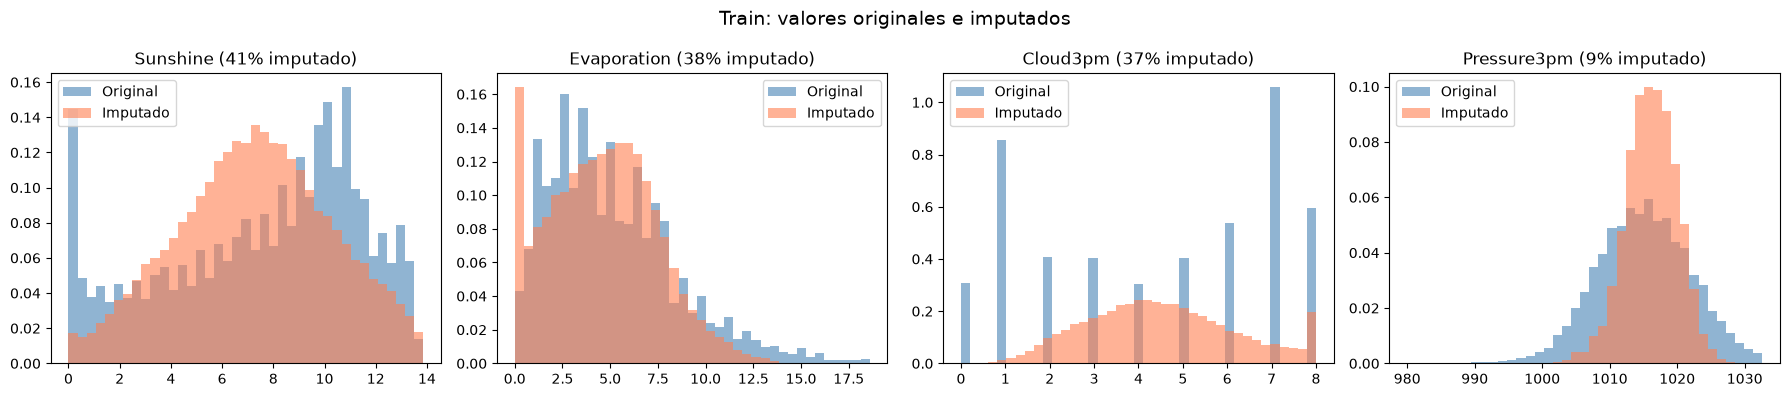

,Sunshine,Evaporation,Cloud3pm,Pressure3pm
Media original,7.60,5.30,4.42,1015.12
Media imputada,7.35,4.65,4.50,1016.16


In [35]:
# Train: distribución de los valores originales y de los imputados en las variables con más faltantes
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['Sunshine', 'Evaporation', 'Cloud3pm', 'Pressure3pm']):
    faltaba = X_train_sin_imputar[col].isna()
    bins = np.linspace(X_train[col].min(), X_train[col].quantile(0.995), 40)
    ax.hist(X_train.loc[~faltaba, col], bins=bins, density=True, alpha=0.6, color='steelblue', label='Original')
    ax.hist(X_train.loc[faltaba, col], bins=bins, density=True, alpha=0.6, color='coral', label='Imputado')
    ax.set_title(f'{col} ({faltaba.mean():.0%} imputado)')
    ax.legend()
plt.suptitle('Train: valores originales e imputados', fontsize=14)
plt.tight_layout()
plt.show()

# Media de los valores originales y de los imputados
pd.DataFrame({col: {'Media original': X_train.loc[X_train_sin_imputar[col].notna(), col].mean(),
                    'Media imputada': X_train.loc[X_train_sin_imputar[col].isna(), col].mean()}
              for col in ['Sunshine', 'Evaporation', 'Cloud3pm', 'Pressure3pm']}).round(2)

Los valores imputados tienen medias similares a las de los originales, pero están más concentrados en el centro de la distribución: el imputador estima el valor esperado a partir de las demás variables del mismo día, así que genera menos valores extremos. 

Por eso: 
- `Cloud` imputada no es bimodal como la original (con más casos en 1 y 7) y toma valores con decimales, 

- `Evaporation` muestra un pico en 0 por el recorte de las estimaciones negativas.

Es una limitación de una **imputación por regresión**. 

### 1.4 Escalado de datos

- `Rainfall` y `Evaporation`: son muy asimétricas y tienen muchos valores extremos (ver 1.1.4). Las escalamos con `RobustScaler`, que resta la mediana y divide por el rango intercuartil (Q3 − Q1). La mediana y los cuartiles casi no dependen de los valores extremos, así que la escala queda definida por la mayoría de los días y no por unos pocos valores muy altos. `RobustScaler` no cambia la forma de la distribución: los valores extremos siguen siendo extremos después del escalado. Por eso, en el boxplot de la derecha recortamos el eje: los valores más altos de `Rainfall` llegan a ~460.
- Resto de las numéricas: `StandardScaler` (media 0 y desvío 1).
- No escalamos las variables cíclicas (ya están entre −1 y 1, y escalar el seno y el coseno por separado deformaría el círculo), 
- No escalamos `RainToday` ni las dummies de región (son 0/1).

In [36]:
# Variables que se escalan: las numéricas continuas
asimetricas = ['Rainfall', 'Evaporation']
resto_numericas = [col for col in columnas_numericas if col not in asimetricas]
cols_escalar = columnas_numericas

X_train_esc, X_val_esc, X_test_esc = X_train.copy(), X_val.copy(), X_test.copy()

# Rainfall y Evaporation: mediana 0 y rango intercuartil 1, con la mediana y los cuartiles de train
escalador_robusto = RobustScaler()
X_train_esc[asimetricas] = escalador_robusto.fit_transform(X_train_esc[asimetricas]) #Calculamos
X_val_esc[asimetricas] = escalador_robusto.transform(X_val_esc[asimetricas])  #Aplicamos
X_test_esc[asimetricas] = escalador_robusto.transform(X_test_esc[asimetricas]) #Aplicamos

# Resto: media 0 y desvío 1, con la media y el desvío de train
escalador = StandardScaler()
X_train_esc[resto_numericas] = escalador.fit_transform(X_train_esc[resto_numericas]) #Calculamos
X_val_esc[resto_numericas] = escalador.transform(X_val_esc[resto_numericas])  #Aplicamos
X_test_esc[resto_numericas] = escalador.transform(X_test_esc[resto_numericas]) #Aplicamos

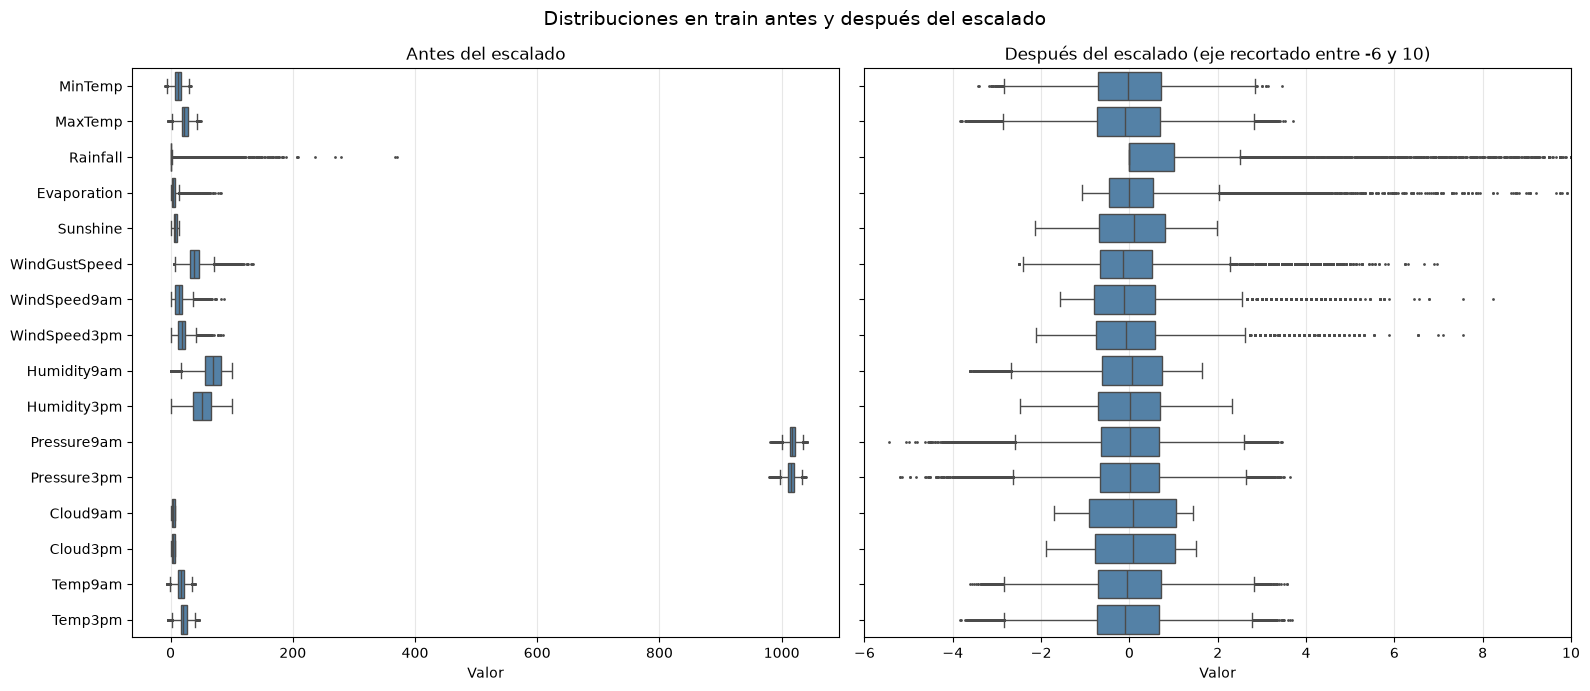

In [37]:
# Boxplots de train antes y después del escalado
cols_escaladas = cols_escalar

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, (titulo, datos) in zip(axes, [('Antes del escalado', X_train),
                                      ('Después del escalado', X_train_esc)]):
    largo = datos[cols_escaladas].melt(var_name='Variable', value_name='Valor')
    sns.boxplot(data=largo, x='Valor', y='Variable', ax=ax, color='steelblue', fliersize=1)
    ax.set_title(titulo)
    ax.set_ylabel('')
    ax.grid(axis='x', alpha=0.3)
# Después del RobustScaler los valores más altos de Rainfall quedan muy lejos del resto: recortamos el eje para ver las demás variables
axes[1].set_xlim(-6, 10)
axes[1].set_title('Después del escalado (eje recortado entre -6 y 10)')
plt.suptitle('Distribuciones en train antes y después del escalado', fontsize=14)
plt.tight_layout()
plt.show()



## 2. Solución con Regresión logística


### 2.1 Entrenamiento

In [38]:
# Se define el modelo de Regresión Logística, con pesos de clase balanceados
logreg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEMILLA)

# Entrenamos solo con train
logreg.fit(X_train_esc, y_train)

# Predicciones con umbral 0.5 y probabilidades de lluvia (clase 1)
y_pred_train = logreg.predict(X_train_esc)
y_pred_val = logreg.predict(X_val_esc)
y_proba_train = logreg.predict_proba(X_train_esc)[:, 1]
y_proba_val = logreg.predict_proba(X_val_esc)[:, 1]

### 2.2 Métricas

Calculamos las métricas en train y validación con el umbral por defecto (0.5). Como referencia, calculamos también el accuracy de predecir siempre "no llueve".

In [39]:
for nombre, y, y_pred, y_proba in [('Train', y_train, y_pred_train, y_proba_train),
                                   ('Validación', y_val, y_pred_val, y_proba_val)]:
    print(f'{nombre} (umbral 0.5) ')
    print(f'Accuracy: {accuracy_score(y, y_pred):.3f}')
    print(f'Accuracy prediciendo siempre "no llueve": {(y == 0).mean():.3f}')
    print(f'ROC AUC: {roc_auc_score(y, y_proba):.3f}')
    print('Reporte de clasificación:')
    print(classification_report(y, y_pred, target_names=['No llueve', 'Llueve'], digits=3))

Train (umbral 0.5) 
Accuracy: 0.795
Accuracy prediciendo siempre "no llueve": 0.774
ROC AUC: 0.875
Reporte de clasificación:
              precision    recall  f1-score   support

   No llueve      0.927     0.798     0.858     77057
      Llueve      0.530     0.783     0.633     22442

    accuracy                          0.795     99499
   macro avg      0.729     0.791     0.745     99499
weighted avg      0.837     0.795     0.807     99499

Validación (umbral 0.5) 
Accuracy: 0.808
Accuracy prediciendo siempre "no llueve": 0.795
ROC AUC: 0.870
Reporte de clasificación:
              precision    recall  f1-score   support

   No llueve      0.926     0.824     0.872     16928
      Llueve      0.522     0.745     0.614      4365

    accuracy                          0.808     21293
   macro avg      0.724     0.784     0.743     21293
weighted avg      0.843     0.808     0.819     21293



**Análisis de las métricas (umbral 0.5)**

- **El accuracy es engañoso.** Prediciendo siempre "no llueve" ya se obtiene 79.5% de accuracy en validación, y la regresión logística llega a 80.8%: parece una mejora mínima. La diferencia real está en la clase "Llueve": el modelo trivial no detecta ningún día de lluvia, y la regresión logística detecta el 75%.
- **Detecta la mayoría de los días de lluvia, con muchas falsas alarmas.** Para la clase "Llueve", el recall es 0.75 (detecta 3 de cada 4 días de lluvia) y la precision 0.52 (cuando dice "llueve", acierta la mitad de las veces). Es la consecuencia esperada de `class_weight='balanced'`, que empuja al modelo a predecir más la clase minoritaria. El F1 macro es 0.74.
- **El modelo ordena bien los días**: ROC AUC 0.870 en validación.
- **No hay sobreajuste notable**: las métricas de train y validación son muy parecidas (ROC AUC 0.875 contra 0.870, F1 de "Llueve" 0.633 contra 0.614). Con 31 variables y ~100.000 días de entrenamiento, una regresión logística tiene poco margen para sobreajustar.

### 2.3 Matriz de confusión

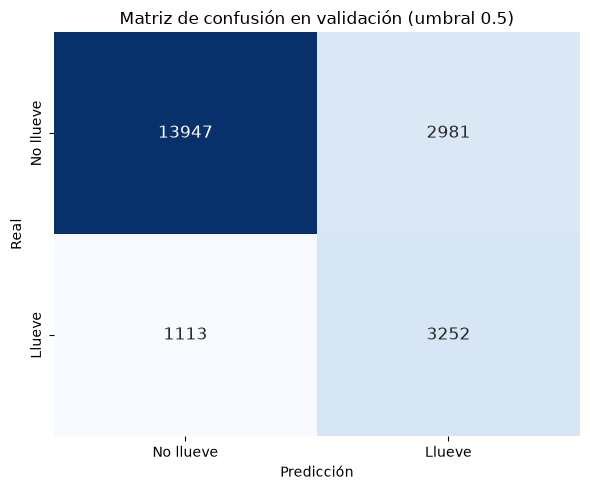

In [40]:
def graficar_confusion(y_true, y_pred, titulo, ax):
    """Matriz de confusión como mapa de calor."""
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No llueve', 'Llueve'], yticklabels=['No llueve', 'Llueve'],
                annot_kws={'size': 12}, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')

fig, ax = plt.subplots(figsize=(6, 5))
graficar_confusion(y_val, y_pred_val, 'Matriz de confusión en validación (umbral 0.5)', ax)
plt.tight_layout()
plt.show()

### 2.4 Falsos positivos y falsos negativos

Con "llueve mañana" como clase positiva:
- **Falso positivo (FP)**: el modelo predice que mañana llueve y no llueve. El costo es una falsa alarma: alguien suspende una actividad, lleva paraguas o reprograma un riego sin necesidad. Muchos FP hacen que la gente deje de confiar en el pronóstico.
- **Falso negativo (FN)**: el modelo predice que mañana no llueve y llueve. El costo es que la lluvia toma a la gente desprevenida: actividades al aire libre, cosechas, obras o logística sin preparar. En general es el error más costoso de los dos.

Para entender en qué se equivoca el modelo, comparamos los valores promedio de algunas variables (sin escalar) en cada celda de la matriz de confusión.

In [41]:
# Promedio de variables clave (sin escalar) según el tipo de acierto/error en validación
variables_clave = ['Humidity3pm', 'Cloud3pm', 'Sunshine', 'Pressure3pm', 'Rainfall', 'RainToday']

errores = X_val[variables_clave].copy()
errores['Prob_lluvia'] = y_proba_val
errores['Tipo'] = np.where(y_val == 1, np.where(y_pred_val == 1, 'VP', 'FN'),
                                       np.where(y_pred_val == 1, 'FP', 'VN'))

resumen_errores = errores.groupby('Tipo').mean().loc[['VP', 'FN', 'FP', 'VN']]
resumen_errores.insert(0, 'Cantidad', errores['Tipo'].value_counts())
resumen_errores.round(2)

,Cantidad,Humidity3pm,Cloud3pm,Sunshine,Pressure3pm,Rainfall,RainToday,Prob_lluvia
Tipo,,,,,,,,
VP,3252,74.27,6.71,3.94,1013.01,7.55,0.56,0.81
FN,1113,48.20,4.35,7.92,1015.48,0.98,0.16,0.30
FP,2981,67.26,6.34,4.82,1014.67,4.29,0.44,0.69
VN,13947,40.94,3.46,9.20,1017.13,0.52,0.08,0.18


**Análisis de los errores (validación, umbral 0.5)**

- **La mayoría de los errores son falsos positivos**: 2981 FP contra 1113 FN. Es lo que se busca con el balanceo de clases: aceptar más falsas alarmas para que se escape menos lluvia.
- **Los FN se parecen a los días secos.** Tienen humedad a las 3 pm de 48% (contra 74% en los VP), cielo menos cubierto (4.3 octas contra 6.7), 7.9 horas de sol (contra 3.9) y presión más alta. Solo el 16% tuvo lluvia ese día. El modelo les asigna en promedio 30% de probabilidad de lluvia. Es lluvia que llega sin señales claras el día anterior (por ejemplo, un frente que entra de golpe), y es difícil de anticipar con los datos disponibles.
- **Los FP se parecen a los días de lluvia.** Tienen humedad de 67%, cielo casi cubierto (6.3 octas), presión baja y el 44% tuvo lluvia ese día. Tenían las señales típicas de lluvia, pero al día siguiente no llovió (o llovió menos de 1 mm, que el dataset cuenta como "no llueve").
- En los dos casos, el modelo se equivoca en días "ambiguos": los FN y los FP tienen valores intermedios entre los de los VN y los VP. Mejorar estos casos requiere información que el modelo no tiene, por ejemplo la evolución de los días anteriores o datos de estaciones vecinas.

### 2.5 Curva ROC

La curva ROC muestra, para cada umbral posible, la tasa de verdaderos positivos (recall, TPR) contra la tasa de falsos positivos (FPR = FP / (FP + VN)). Un modelo al azar queda sobre la diagonal, y cuanto más se acerca la curva a la esquina superior izquierda, mejor. Graficamos la curva de validación junto con la de train (si estuvieran muy separadas, habría sobreajuste) y marcamos el punto que corresponde al umbral 0.5.

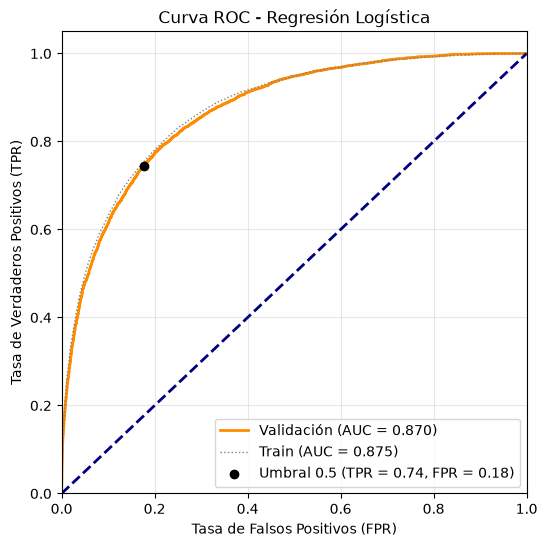

In [42]:
# Calculamos la ROC y el AUC en train y validación
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_proba_train)
fpr, tpr, thresholds = roc_curve(y_val, y_proba_val)
roc_auc_train = auc(fpr_train, tpr_train)
roc_auc = auc(fpr, tpr)

# Punto de la curva de validación que corresponde al umbral 0.5
i_05 = np.argmin(np.abs(thresholds - 0.5))

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Validación (AUC = %0.3f)' % roc_auc)
plt.plot(fpr_train, tpr_train, color='gray', lw=1, linestyle=':', label='Train (AUC = %0.3f)' % roc_auc_train)
plt.scatter(fpr[i_05], tpr[i_05], color='black', zorder=3,
            label=f'Umbral 0.5 (TPR = {tpr[i_05]:.2f}, FPR = {fpr[i_05]:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Regresión Logística')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

### 2.6 Elección del umbral

- El modelo devuelve una probabilidad, y el umbral decide a partir de qué probabilidad predecimos. 
    - Al bajar el umbral detectamos más días de lluvia (sube el recall), pero también aumentan las falsas alarmas (baja la precision). 
    
- 0.5 sería es el umbral natural sólo si las clases estuvieran balanceadas y los dos errores costarían lo mismo.

Formas de calcular el mejor umbral:
- **Índice de Youden**: el umbral de la curva ROC que maximiza TPR − FPR, es decir, el punto más alejado de la diagonal. Sale directamente de los `thresholds` que devuelve `roc_curve`.
- **Máximo F1**: busca el mejor equilibrio entre precision y recall de la clase positiva.
- **Máximo F1 macro**: busca el mejor equilibrio entre el F1 de las dos clases, con el mismo peso para cada una.
- **Por costos**: si un falso negativo cuesta *k* veces más que un falso positivo, elegimos el umbral que minimiza `k·FN + FP`. Usamos *k* = 3 como supuesto.

Para los tres últimos criterios recorremos una grilla de umbrales y calculamos el reporte de clasificación y la matriz de confusión en cada uno. El umbral se elige en **validación**, nunca en test: si lo eligiéramos en test, la evaluación final sería optimista.

In [43]:
COSTO_FN = 3  # supuesto: no anticipar la lluvia cuesta 3 veces más que una falsa alarma

def metricas_umbral(y_true, y_proba, umbral):
    """Métricas del reporte de clasificación y errores de la matriz de confusión para un umbral."""
    y_pred = (y_proba >= umbral).astype(int)
    reporte = classification_report(y_true, y_pred, target_names=['No llueve', 'Llueve'], output_dict=True)
    vn, fp, fn, vp = confusion_matrix(y_true, y_pred).ravel()
    return {'Umbral': umbral,
            'Accuracy': reporte['accuracy'],
            'Precision': reporte['Llueve']['precision'],
            'Recall': reporte['Llueve']['recall'],
            'F1': reporte['Llueve']['f1-score'],
            'F1 macro': reporte['macro avg']['f1-score'],
            'FP': fp, 'FN': fn, 'Costo': COSTO_FN * fn + fp}

# Métricas en validación para una grilla de umbrales
curvas = pd.DataFrame([metricas_umbral(y_val, y_proba_val, u)
                       for u in np.arange(0.05, 0.96, 0.01).round(2)]).set_index('Umbral')

umbrales_candidatos = {
    '0.5 (por defecto)': 0.5,
    'Youden': thresholds[np.argmax(tpr - fpr)],   # sale de la curva ROC de validación
    'Máximo F1': curvas['F1'].idxmax(),
    'Máximo F1 macro': curvas['F1 macro'].idxmax(),
    f'Mínimo costo (FN = {COSTO_FN} FP)': curvas['Costo'].idxmin(),
}
tabla_umbrales = pd.DataFrame([{'Criterio': criterio, **metricas_umbral(y_val, y_proba_val, u)}
                               for criterio, u in umbrales_candidatos.items()]).set_index('Criterio')

# Umbral que usamos en la evaluación final (cambiar el criterio acá si se prefiere otro)
CRITERIO = 'Máximo F1 macro'
umbral_elegido = umbrales_candidatos[CRITERIO]
print(f'Umbral elegido ({CRITERIO}): {umbral_elegido:.2f}')
tabla_umbrales.round(3)

Umbral elegido (Máximo F1 macro): 0.64


,Umbral,Accuracy,Precision,Recall,F1,F1 macro,FP,FN,Costo
Criterio,,,,,,,,,
0.5 (por defecto),0.50,0.808,0.522,0.745,0.614,0.743,2981,1113,6320
Youden,0.44,0.785,0.485,0.790,0.601,0.727,3658,916,6406
Máximo F1,0.62,0.837,0.595,0.643,0.618,0.757,1913,1558,6587
Máximo F1 macro,0.64,0.841,0.608,0.625,0.617,0.758,1758,1636,6666
Mínimo costo (FN = 3 FP),0.50,0.808,0.522,0.745,0.614,0.743,2981,1113,6320


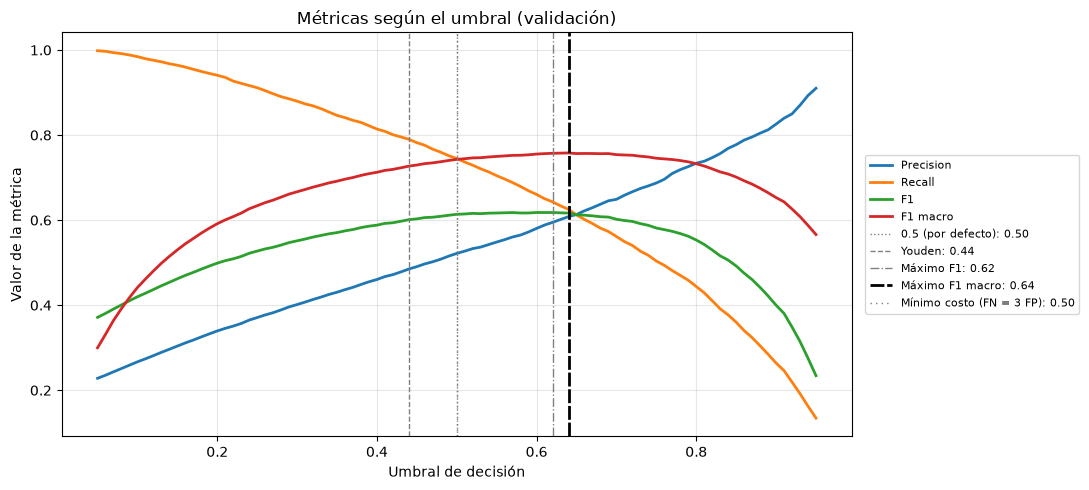

In [44]:
# Cómo cambian las métricas al mover el umbral (validación)
plt.figure(figsize=(11, 5))
for metrica in ['Precision', 'Recall', 'F1', 'F1 macro']:
    plt.plot(curvas.index, curvas[metrica], lw=2, label=metrica)

estilos = [':', '--', '-.', (0, (5, 1)), (0, (1, 3))]
for (criterio, umbral), estilo in zip(umbrales_candidatos.items(), estilos):
    plt.axvline(umbral, color='black' if criterio == CRITERIO else 'gray', linestyle=estilo,
                lw=2 if criterio == CRITERIO else 1, label=f'{criterio}: {umbral:.2f}')

plt.xlabel('Umbral de decisión')
plt.ylabel('Valor de la métrica')
plt.title('Métricas según el umbral (validación)')
plt.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análisis de la curva ROC y del umbral (validación)**

- **La curva ROC de validación (AUC 0.870) está casi superpuesta con la de train (0.875)**: el modelo generaliza bien. Con umbral 0.5 opera en TPR = 0.75 y FPR = 0.18.
- **0.5 no es necesariamente el mejor umbral, pero acá queda cerca de los óptimos.** Como el modelo se entrenó con `class_weight='balanced'`, la corrección por el desbalance ya está hecha en el entrenamiento. Sin balancear, los óptimos quedarían muy por debajo de 0.5 (el modelo sin balancear detecta solo el 47% de los días de lluvia con 0.5).
- **Cada criterio elige un punto distinto de la curva:**
  - **Youden (0.44)** maximiza TPR − FPR: detecta el 79% de la lluvia, con precision 0.49.
  - **Mínimo costo con FN = 3 FP (0.50)** coincide con el umbral por defecto: recall 0.75 y precision 0.52.
  - **Máximo F1 (0.62)** y **máximo F1 macro (0.64)** suben el umbral: menos falsas alarmas (precision ~0.59–0.61) a cambio de detectar menos lluvia (recall ~0.63–0.64).
- **Elegimos el máximo F1 macro (0.64)**, que da el mismo peso al acierto en días secos y en días de lluvia. Respecto de 0.5, los FP bajan de 2981 a 1758 (−41%) y los FN suben de 1113 a 1636 (+47%).
- **Si se considera que no anticipar la lluvia es bastante más costoso que una falsa alarma** (como planteamos en 2.4), el criterio de costo, que en este caso coincide con 0.5, sería más adecuado. Entre 0.5 y 0.65 las curvas de F1 y F1 macro son casi planas, así que el umbral cambia poco esas métricas, pero sí cambia mucho el balance entre FP y FN.
- El umbral queda fijo con lo que vimos en validación, y se aplica una sola vez sobre test.

### 2.7 Evaluación final en test

Con el modelo entrenado y el umbral elegido en validación, evaluamos una sola vez sobre test. Mostramos también el umbral 0.5 como referencia. Ningún resultado de esta sección se usa para modificar el modelo ni el umbral.

In [45]:
y_proba_test = logreg.predict_proba(X_test_esc)[:, 1]
y_pred_test_05 = (y_proba_test >= 0.5).astype(int)
y_pred_test = (y_proba_test >= umbral_elegido).astype(int)

print(f'Accuracy prediciendo siempre "no llueve": {(y_test == 0).mean():.3f}')
print(f'ROC AUC: {roc_auc_score(y_test, y_proba_test):.3f}')
for titulo, y_pred in [('umbral 0.5', y_pred_test_05), (f'umbral elegido ({umbral_elegido:.2f})', y_pred_test)]:
    print(f'\n===== Test, {titulo} =====')
    print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
    print(classification_report(y_test, y_pred, target_names=['No llueve', 'Llueve'], digits=3))

Accuracy prediciendo siempre "no llueve": 0.763
ROC AUC: 0.861

===== Test, umbral 0.5 =====
Accuracy: 0.777
              precision    recall  f1-score   support

   No llueve      0.921     0.773     0.841     16296
      Llueve      0.519     0.788     0.626      5065

    accuracy                          0.777     21361
   macro avg      0.720     0.780     0.733     21361
weighted avg      0.826     0.777     0.790     21361


===== Test, umbral elegido (0.64) =====
Accuracy: 0.818
              precision    recall  f1-score   support

   No llueve      0.895     0.862     0.878     16296
      Llueve      0.604     0.674     0.637      5065

    accuracy                          0.818     21361
   macro avg      0.749     0.768     0.758     21361
weighted avg      0.826     0.818     0.821     21361



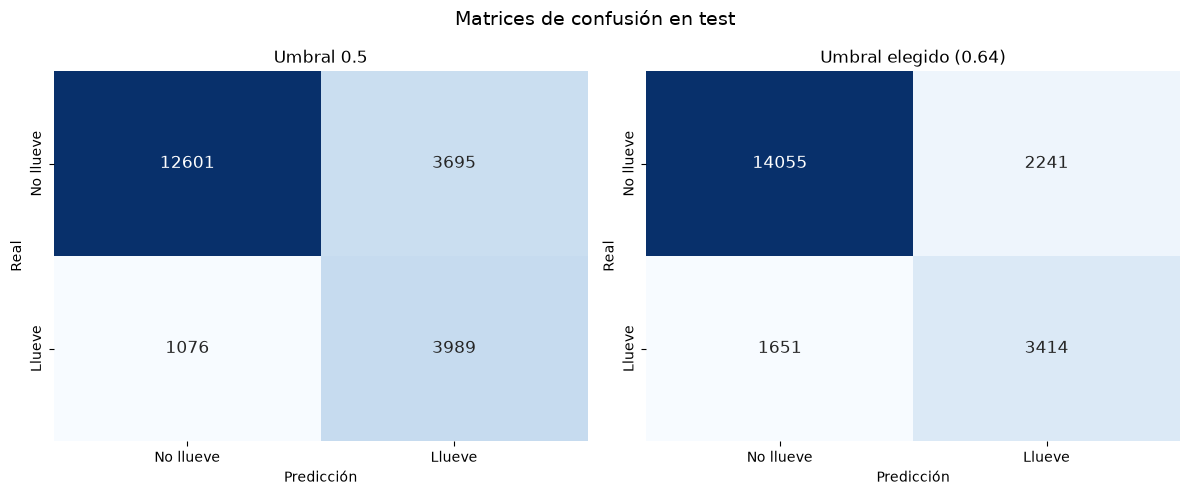

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
graficar_confusion(y_test, y_pred_test_05, 'Umbral 0.5', axes[0])
graficar_confusion(y_test, y_pred_test, f'Umbral elegido ({umbral_elegido:.2f})', axes[1])
plt.suptitle('Matrices de confusión en test', fontsize=14)
plt.tight_layout()
plt.show()

In [47]:
# Mismas métricas en los tres conjuntos con el umbral elegido: si train fuera mucho mejor, habría sobreajuste
comparacion = pd.DataFrame({
    nombre: {**metricas_umbral(y, y_proba, umbral_elegido), 'ROC AUC': roc_auc_score(y, y_proba)}
    for nombre, y, y_proba in [('Train', y_train, y_proba_train),
                               ('Validación', y_val, y_proba_val),
                               ('Test', y_test, y_proba_test)]
}).drop(['Umbral', 'FP', 'FN', 'Costo'])
comparacion.round(3)

,Train,Validación,Test
Accuracy,0.833,0.841,0.818
Precision,0.620,0.608,0.604
Recall,0.673,0.625,0.674
F1,0.646,0.617,0.637
F1 macro,0.768,0.758,0.758
ROC AUC,0.875,0.870,0.861


**Conclusiones de la evaluación en test**

- **Los resultados en test confirman los de validación.** Con el umbral elegido (0.64): F1 macro 0.758 (igual que en validación); para la clase "Llueve", F1 0.637, recall 0.67 y precision 0.60. El ROC AUC es 0.861, apenas por debajo de validación (0.870) y train (0.875).
- **Frente a predecir siempre "no llueve"** (accuracy 0.763 en test), la regresión logística llega a 0.818 de accuracy, pero la diferencia real está en la clase "Llueve": detecta el 67% de los días de lluvia, mientras que el modelo trivial no detecta ninguno.
- **El cambio de umbral se comporta igual que en validación**: pasar de 0.5 a 0.64 sube la precision (0.52 → 0.60), baja el recall (0.79 → 0.67) y mejora el F1 macro (0.733 → 0.758).
- **No hay sobreajuste**: train, validación y test tienen métricas muy parecidas. Las pequeñas diferencias se deben a que cada conjunto cubre un período distinto, con distinta proporción de días de lluvia (22.6% en train, 20.5% en validación y 23.7% en test).

## 3. Modelo base

Como modelo base usamos un modelo de **persistencia**: predice que mañana llueve si hoy llovió (`RainToday = 1`) y que no llueve en caso contrario. Es una referencia clásica en meteorología, porque el tiempo de un día suele parecerse al del día anterior. No aprende nada de los datos, así que sirve para medir cuánto aporta la regresión logística por encima de una regla simple.

Usamos `RainToday` después de la imputación (los pocos faltantes se completaron a partir de `Rainfall`). De los pasos del punto 2 repetimos las métricas, la matriz de confusión, el análisis de FP y FN, la curva ROC y la evaluación en test. No hay entrenamiento ni umbral que elegir, porque la predicción ya es 0 o 1.

### 3.1 Predicciones

In [48]:
# Persistencia: mañana llueve si hoy llovió
y_pred_train_pers = X_train['RainToday'].astype(int).values
y_pred_val_pers = X_val['RainToday'].astype(int).values
y_pred_test_pers = X_test['RainToday'].astype(int).values

### 3.2 Métricas

In [49]:
# Métricas de la persistencia en train y validación
for nombre, y, y_pred in [('Train', y_train, y_pred_train_pers), ('Validación', y_val, y_pred_val_pers)]:
    print(f'===== Persistencia - {nombre} =====')
    print(f'Accuracy: {accuracy_score(y, y_pred):.3f}')
    print(f'ROC AUC: {roc_auc_score(y, y_pred):.3f}')
    print('Reporte de clasificación:')
    print(classification_report(y, y_pred, target_names=['No llueve', 'Llueve'], digits=3))

===== Persistencia - Train =====
Accuracy: 0.762
ROC AUC: 0.662
Reporte de clasificación:
              precision    recall  f1-score   support

   No llueve      0.848     0.843     0.846     77057
      Llueve      0.472     0.482     0.477     22442

    accuracy                          0.762     99499
   macro avg      0.660     0.662     0.661     99499
weighted avg      0.763     0.762     0.762     99499

===== Persistencia - Validación =====
Accuracy: 0.775
ROC AUC: 0.659
Reporte de clasificación:
              precision    recall  f1-score   support

   No llueve      0.860     0.855     0.858     16928
      Llueve      0.452     0.462     0.457      4365

    accuracy                          0.775     21293
   macro avg      0.656     0.659     0.657     21293
weighted avg      0.777     0.775     0.776     21293



In [50]:
# Comparación con la regresión logística del punto 2 en validación
comparacion_val = pd.DataFrame([
    {**metricas_umbral(y_val, y_pred_val_pers, 0.5), 'ROC AUC': roc_auc_score(y_val, y_pred_val_pers)},
    {**metricas_umbral(y_val, y_proba_val, 0.5), 'ROC AUC': roc_auc_score(y_val, y_proba_val)},
    {**metricas_umbral(y_val, y_proba_val, umbral_elegido), 'ROC AUC': roc_auc_score(y_val, y_proba_val)},
], index=['Persistencia', 'RL balanceada, umbral 0.5', f'RL balanceada, umbral {umbral_elegido:.2f}'])
comparacion_val.drop(columns=['Umbral', 'Costo']).round(3)

,Accuracy,Precision,Recall,F1,F1 macro,FP,FN,ROC AUC
Persistencia,0.775,0.452,0.462,0.457,0.657,2447,2350,0.659
"RL balanceada, umbral 0.5",0.808,0.522,0.745,0.614,0.743,2981,1113,0.870
"RL balanceada, umbral 0.64",0.841,0.608,0.625,0.617,0.758,1758,1636,0.870


**Análisis de las métricas**

- La persistencia acierta en el 77.5% de los días de validación, menos que predecir siempre "no llueve" (79.5%). Se equivoca en los dos sentidos: no anticipa la lluvia que empieza y anuncia lluvia el día en que termina.
- Para la clase "Llueve" tiene precision 0.45 y recall 0.46: detecta menos de la mitad de los días de lluvia y, cuando dice "llueve", acierta menos de la mitad de las veces. El F1 macro es 0.657.
- La regresión logística del punto 2 la supera en todas las métricas. Con su umbral elegido (0.64) tiene F1 macro 0.758, precision 0.61 y recall 0.63, y comete menos FP (1758 contra 2447) y menos FN (1636 contra 2350).
- Como la persistencia no aprende nada de los datos, sus métricas en train y validación son parecidas (F1 macro 0.661 y 0.657) y no tiene sentido hablar de sobreajuste.

### 3.3 Matriz de confusión, falsos positivos y falsos negativos

En la persistencia, los errores tienen una interpretación directa:
- **FN**: hoy no llovió y mañana sí. Es la lluvia que empieza, y la persistencia nunca la puede anticipar.
- **FP**: hoy llovió y mañana no. Es la lluvia que termina.

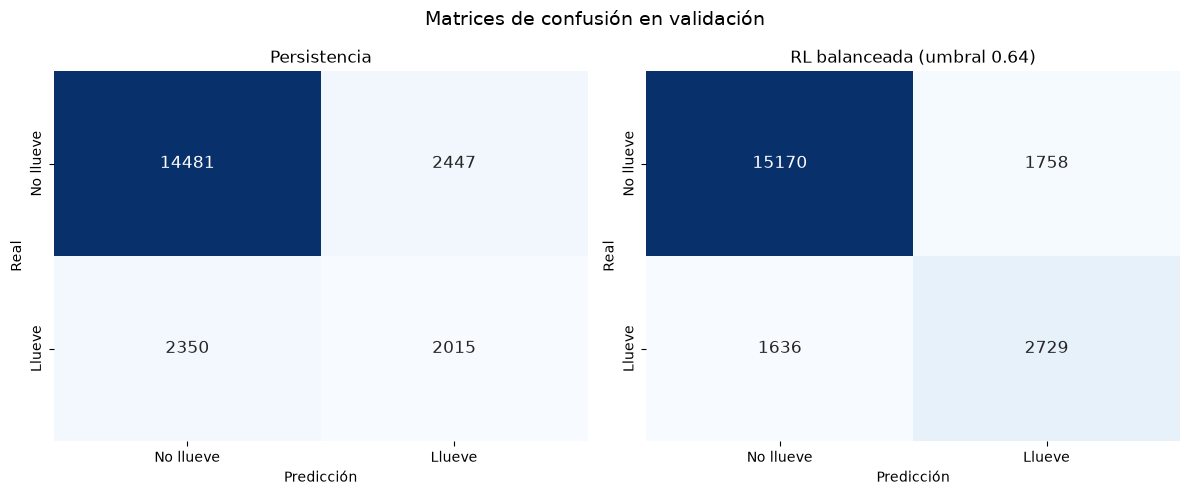

In [51]:
# Matrices de confusión en validación: persistencia y regresión logística con su umbral elegido
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
graficar_confusion(y_val, y_pred_val_pers, 'Persistencia', axes[0])
graficar_confusion(y_val, (y_proba_val >= umbral_elegido).astype(int),
                   f'RL balanceada (umbral {umbral_elegido:.2f})', axes[1])
plt.suptitle('Matrices de confusión en validación', fontsize=14)
plt.tight_layout()
plt.show()

In [52]:
# Promedio de variables clave según el tipo de acierto/error de la persistencia (validación),
# junto con la probabilidad de lluvia que les asigna la regresión logística
errores_pers = X_val[variables_clave].copy()
errores_pers['Prob_lluvia_RL'] = y_proba_val
errores_pers['Tipo'] = np.where(y_val == 1, np.where(y_pred_val_pers == 1, 'VP', 'FN'),
                                            np.where(y_pred_val_pers == 1, 'FP', 'VN'))

# Errores de la persistencia que la regresión logística evita con su umbral elegido
es_fn = (errores_pers['Tipo'] == 'FN').values
es_fp = (errores_pers['Tipo'] == 'FP').values
print(f'FN de la persistencia que la RL detecta: {(y_proba_val[es_fn] >= umbral_elegido).mean():.0%}')
print(f'FP de la persistencia que la RL clasifica bien: {(y_proba_val[es_fp] < umbral_elegido).mean():.0%}')

resumen_errores_pers = errores_pers.groupby('Tipo').mean().loc[['VP', 'FN', 'FP', 'VN']]
resumen_errores_pers.insert(0, 'Cantidad', errores_pers['Tipo'].value_counts())
resumen_errores_pers.round(2)

FN de la persistencia que la RL detecta: 45%
FP de la persistencia que la RL clasifica bien: 63%


,Cantidad,Humidity3pm,Cloud3pm,Sunshine,Pressure3pm,Rainfall,RainToday,Prob_lluvia_RL
Tipo,,,,,,,,
VP,2015,74.43,6.49,3.99,1013.70,12.56,1.0,0.81
FN,2350,61.79,5.78,5.78,1013.59,0.14,0.0,0.57
FP,2447,58.44,5.09,6.52,1016.20,7.83,1.0,0.53
VN,14481,43.40,3.77,8.75,1016.78,0.06,0.0,0.22


**Análisis de los errores de la persistencia (validación)**

- La persistencia comete casi la misma cantidad de FN (2350) que de FP (2447).
- Los FN son días secos seguidos de un día de lluvia. La persistencia nunca los puede detectar, pero esos días ya muestran señales de lluvia: humedad a las 3 pm de 62%, 5.8 octas de nubosidad y presión de 1013.6 hPa, valores más cercanos a los de los VP que a los de los VN. La regresión logística detecta el 45% de ellos.
- Los FP son días de lluvia seguidos de un día seco. Tienen menos humedad (58%), menos nubosidad (5.1 octas) y presión más alta (1016.2 hPa) que los VP: son días en los que la lluvia está terminando. La regresión logística clasifica bien el 63% de ellos.
- La persistencia solo mira si llovió hoy. La regresión logística usa además la humedad, la nubosidad, la presión y el resto de las variables, y por eso puede distinguir en muchos casos entre la lluvia que empieza y la que termina.

### 3.4 Curva ROC

Como la persistencia predice directamente 0 o 1, no tiene una curva ROC sino un único punto (FPR, TPR), y no hay umbral que elegir. La comparamos con la curva ROC de validación de la regresión logística del punto 2.

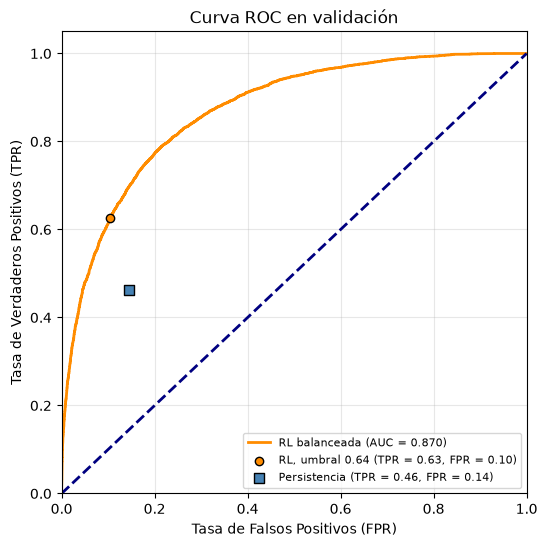

Con FPR = 0.14, la persistencia detecta el 46% de los días de lluvia y la regresión logística el 70%


In [53]:
# Punto (FPR, TPR) de la persistencia en validación
vn_p, fp_p, fn_p, vp_p = confusion_matrix(y_val, y_pred_val_pers).ravel()
fpr_pers = fp_p / (fp_p + vn_p)
tpr_pers = vp_p / (vp_p + fn_p)

# Punto de la curva de la regresión logística que corresponde a su umbral elegido
i_elegido = np.argmin(np.abs(thresholds - umbral_elegido))

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='RL balanceada (AUC = %0.3f)' % roc_auc)
plt.scatter(fpr[i_elegido], tpr[i_elegido], color='darkorange', edgecolor='black', zorder=3,
            label=f'RL, umbral {umbral_elegido:.2f} (TPR = {tpr[i_elegido]:.2f}, FPR = {fpr[i_elegido]:.2f})')
plt.scatter(fpr_pers, tpr_pers, color='steelblue', marker='s', s=60, edgecolor='black', zorder=3,
            label=f'Persistencia (TPR = {tpr_pers:.2f}, FPR = {fpr_pers:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC en validación')
plt.legend(loc='lower right', fontsize=8)
plt.grid(alpha=0.3)
plt.show()

# TPR de la regresión logística con la misma tasa de falsos positivos que la persistencia
tpr_rl_mismo_fpr = np.interp(fpr_pers, fpr, tpr)
print(f'Con FPR = {fpr_pers:.2f}, la persistencia detecta el {tpr_pers:.0%} de los días de lluvia '
      f'y la regresión logística el {tpr_rl_mismo_fpr:.0%}')

**Análisis de la curva ROC**

- El punto de la persistencia (TPR = 0.46, FPR = 0.14) queda muy por debajo de la curva de la regresión logística. Con la misma tasa de falsos positivos, la regresión logística detecta el 70% de los días de lluvia, contra 46% de la persistencia.
- El ROC AUC de la persistencia es 0.659, contra 0.870 de la regresión logística. Para un clasificador que predice solo 0 o 1, el AUC es el promedio del recall de las dos clases.
- La regresión logística con su umbral elegido (0.64) tiene a la vez más TPR (0.63) y menos FPR (0.10) que la persistencia: es mejor en los dos tipos de error.

### 3.5 Evaluación final en test y comparación con el punto 2

In [54]:
# Persistencia en test
print(f'Accuracy: {accuracy_score(y_test, y_pred_test_pers):.3f}')
print(f'ROC AUC: {roc_auc_score(y_test, y_pred_test_pers):.3f}')
print(classification_report(y_test, y_pred_test_pers, target_names=['No llueve', 'Llueve'], digits=3))

Accuracy: 0.742
ROC AUC: 0.647
              precision    recall  f1-score   support

   No llueve      0.833     0.827     0.830     16296
      Llueve      0.457     0.467     0.462      5065

    accuracy                          0.742     21361
   macro avg      0.645     0.647     0.646     21361
weighted avg      0.744     0.742     0.743     21361



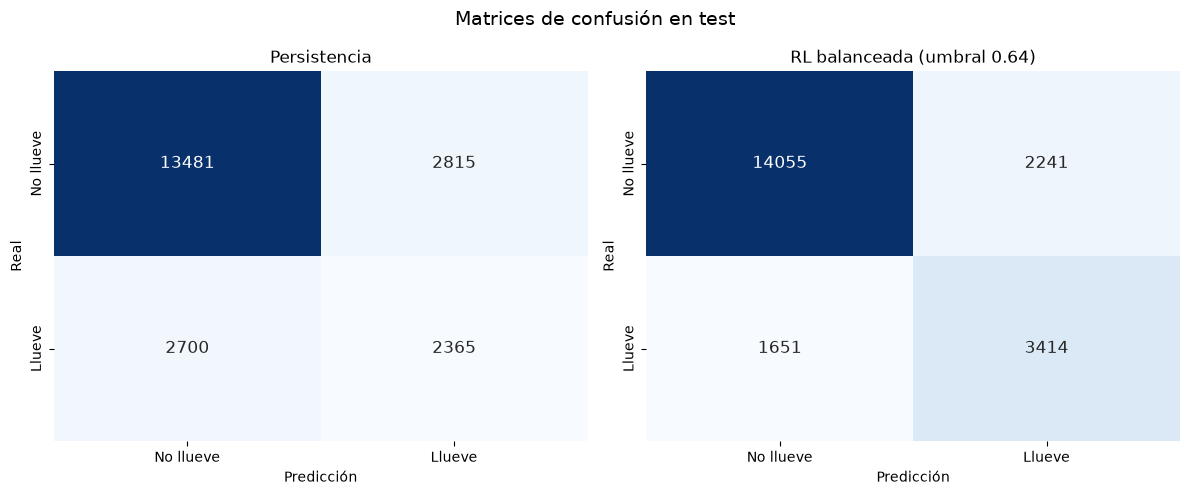

In [55]:
# Matrices de confusión en test: persistencia y regresión logística con su umbral elegido
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
graficar_confusion(y_test, y_pred_test_pers, 'Persistencia', axes[0])
graficar_confusion(y_test, y_pred_test, f'RL balanceada (umbral {umbral_elegido:.2f})', axes[1])
plt.suptitle('Matrices de confusión en test', fontsize=14)
plt.tight_layout()
plt.show()

In [56]:
# Comparación en test con la regresión logística del punto 2
comparacion_test = pd.DataFrame([
    {**metricas_umbral(y_test, y_pred_test_pers, 0.5), 'ROC AUC': roc_auc_score(y_test, y_pred_test_pers)},
    {**metricas_umbral(y_test, y_proba_test, 0.5), 'ROC AUC': roc_auc_score(y_test, y_proba_test)},
    {**metricas_umbral(y_test, y_proba_test, umbral_elegido), 'ROC AUC': roc_auc_score(y_test, y_proba_test)},
], index=['Persistencia', 'RL balanceada, umbral 0.5', f'RL balanceada, umbral {umbral_elegido:.2f}'])
comparacion_test.drop(columns=['Umbral', 'Costo']).round(3)

,Accuracy,Precision,Recall,F1,F1 macro,FP,FN,ROC AUC
Persistencia,0.742,0.457,0.467,0.462,0.646,2815,2700,0.647
"RL balanceada, umbral 0.5",0.777,0.519,0.788,0.626,0.733,3695,1076,0.861
"RL balanceada, umbral 0.64",0.818,0.604,0.674,0.637,0.758,2241,1651,0.861


In [57]:
# Estabilidad de la persistencia en los tres conjuntos
comparacion_pers = pd.DataFrame({
    nombre: {**metricas_umbral(y, y_pred, 0.5), 'ROC AUC': roc_auc_score(y, y_pred)}
    for nombre, y, y_pred in [('Train', y_train, y_pred_train_pers),
                              ('Validación', y_val, y_pred_val_pers),
                              ('Test', y_test, y_pred_test_pers)]
}).drop(['Umbral', 'FP', 'FN', 'Costo'])
comparacion_pers.round(3)

,Train,Validación,Test
Accuracy,0.762,0.775,0.742
Precision,0.472,0.452,0.457
Recall,0.482,0.462,0.467
F1,0.477,0.457,0.462
F1 macro,0.661,0.657,0.646
ROC AUC,0.662,0.659,0.647


**Conclusiones del modelo base**

- En test, la persistencia obtiene F1 macro 0.646, con precision 0.46 y recall 0.47 para la clase "Llueve". Su accuracy (0.742) es menor que el de predecir siempre "no llueve" (0.763).
- La regresión logística con su umbral elegido obtiene F1 macro 0.758, precision 0.60 y recall 0.67, y comete menos FP (2241 contra 2815) y menos FN (1651 contra 2700). El ROC AUC sube de 0.647 a 0.861.
- La persistencia da resultados estables en los tres conjuntos (F1 macro entre 0.646 y 0.661), porque no depende de ningún entrenamiento.
- Saber si llovió hoy aporta información, pero no alcanza. La regresión logística mejora claramente sobre la persistencia porque combina `RainToday` con la humedad, la nubosidad, la presión y el resto de las variables.